In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, median_absolute_error, r2_score
from sklearn.metrics import balanced_accuracy_score, precision_score, average_precision_score, roc_auc_score, recall_score, cohen_kappa_score, matthews_corrcoef, f1_score
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import pearsonr

plt.rcParams.update({'font.size': 15, 'grid.color': 'gray', 'grid.linestyle': '--'  })
colors = ["#F35965", "#6BF178", "#3EA7FF", "#8633A8", "#30D5C8", "#DC8DC4"]

smiles = pd.read_csv('../datasets/druglike_b3db_labelled_outerfolds.csv')['smiles']

true_ds = pd.read_csv('../datasets/druglike_b3db_labelled_outerfolds.csv')
pred_df = pd.read_csv(f'./random_outerfolds/custom_mtl_bab_results/custom_mtl_predictions.csv')


data_path = f'./random_outerfolds/custom_mtl_bab_results/custom_mtl_predictions.csv'

raw_results_df = pd.read_csv(data_path)
bbb_class = np.array(true_ds['bbb_class'])
logbb = np.array(true_ds['logBB'])

predicted_bbb_class = pred_df['predicted_bbb_class']
predicted_logBB = pred_df['predicted_logBB']

 bandwidth_score  n_penetrant  n_nonpenetrant  peak_penetrant  peak_nonpenetrant  peak_gap_score  peak_gap_logBB
            0.15         2220             968          3.1424             1.9692          1.1731          0.8798
            0.20         2220             968          3.1087             1.9644          1.1442          0.8582
            0.25         2220             968          3.0605             1.9756          1.0849          0.8137


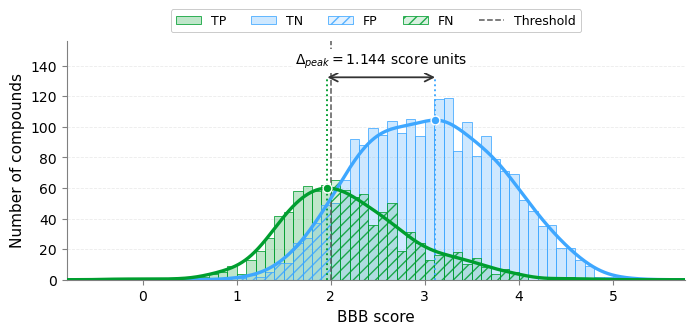

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from scipy.stats import gaussian_kde

def plot_score_peaks(scores, labels, title='', threshold=2., binwidth=.1, bandwidth=.20, ax=None):
    scores, labels = np.asarray(scores, float).ravel(), np.asarray(labels).ravel()
    if scores.shape != labels.shape: raise ValueError('Scores and labels must align molecule by molecule')
    if not np.isfinite(scores).all() or not np.isin(labels, [0, 1]).all():
        raise ValueError('Need finite scores and labels 0/1; no rows are automatically removed')

    class0, class1 = scores[labels == 0], scores[labels == 1]
    if any(len(c) < 2 or np.std(c, ddof=1) == 0 for c in [class0, class1]):
        raise ValueError('Each class needs at least two scores and nonzero variance')

    # Smooth the full true-class distributions using the same bandwidth.
    x = np.linspace(scores.min()-3*bandwidth, scores.max()+3*bandwidth, 4096)

    def densities(h):
        return [gaussian_kde(c, bw_method=h/np.std(c, ddof=1))(x) for c in [class0, class1]]

    kde0, kde1 = densities(bandwidth)
    peak0, peak1 = x[np.argmax(kde0)], x[np.argmax(kde1)]
    gap = abs(peak0-peak1)

    # Shared histogram bins, with the threshold on a bin boundary.
    edges = threshold + binwidth*np.arange(
        np.floor((scores.min()-threshold)/binwidth),
        np.ceil((scores.max()-threshold)/binwidth)+2
    )

    if ax is None: _, ax = plt.subplots(figsize=(7.2, 3.6))
    blue, green = '#3EA7FF', '#009E2F'

    # Transparent fills with stronger outlines of the same color.
    for vals, color, hatch, label in [
        (class1[class1 < threshold], green, '', 'TP'),
        (class0[class0 >= threshold], blue, '', 'TN'),
        (class0[class0 < threshold], blue, '///', 'FP'),
        (class1[class1 >= threshold], green, '///', 'FN'),
    ]:
        ax.hist(
            vals, bins=edges,
            facecolor=to_rgba(color, .15 if hatch else .25),
            edgecolor=to_rgba(color, .85),
            linewidth=.65, hatch=hatch, label=label, zorder=2
        )

    # KDE outlines scaled to the histogram's count axis.
    for density, c, peak, color in [
        (kde0, class0, peak0, blue),
        (kde1, class1, peak1, green)
    ]:
        curve = density*len(c)*binwidth
        ax.plot(x, curve, color=color, lw=2.4, zorder=5)
        ax.scatter(peak, curve[np.argmax(density)], color=color,
                   edgecolor='white', s=40, zorder=6)

    ax.axvline(threshold, color='.35', ls='--', lw=1.1,
               label='Threshold', zorder=3)

    # Vertical peak guides, connecting arrow, and distance above.
    ymax = ax.get_ylim()[1]
    arrow_y = ymax*1.06
    ax.set_ylim(0, ymax*1.25)
    ax.set_xlim(-1, 6)

    for peak, color in [(peak0, blue), (peak1, green)]:
        ax.vlines(peak, 0, arrow_y, colors=color,
                  linestyles=':', linewidth=1.35, zorder=4)

    ax.annotate(
        '', xy=(peak0, arrow_y), xytext=(peak1, arrow_y), zorder=7,
        arrowprops=dict(arrowstyle='<->', color='.2', lw=1.3, shrinkA=0, shrinkB=0)
    )
    ax.text(
        (peak0+peak1)/2, arrow_y+.035*ymax,
        rf'$\Delta_{{peak}}={gap:.3f}$ score units',
        ha='center', va='bottom', fontsize=10, zorder=7,
        bbox=dict(facecolor='white', edgecolor='none', pad=1.5)
    )

    ax.set(xlabel='BBB score', ylabel='Number of compounds',
           xlim=(x.min(), x.max()), facecolor='white')
    ax.set_title(title, loc='left', fontsize=12, pad=36)
    ax.spines[['top', 'right']].set_visible(False)
    for spine in ['left', 'bottom']: ax.spines[spine].set_color('.5')
    ax.tick_params(labelsize=10, color='.5')
    ax.xaxis.label.set_size(11)
    ax.yaxis.label.set_size(11)
    ax.grid(False)
    ax.grid(axis='y', color='.92', linewidth=.6)
    ax.set_axisbelow(True)

    legend = ax.legend(
        loc='lower center', bbox_to_anchor=(.5, 1.01), ncol=5,
        fontsize=9, frameon=True, facecolor='white', edgecolor='.7'
    )
    legend.get_frame().set_linewidth(.6)

    # Check bandwidth sensitivity; these are not confidence intervals.
    rows = []
    for factor in [.75, 1., 1.25]:
        d0, d1 = (kde0, kde1) if factor == 1 else densities(bandwidth*factor)
        p0, p1 = x[np.argmax(d0)], x[np.argmax(d1)]
        rows.append({
            'bandwidth_score': bandwidth*factor,
            'n_penetrant': len(class0),
            'n_nonpenetrant': len(class1),
            'peak_penetrant': p0,
            'peak_nonpenetrant': p1,
            'peak_gap_score': abs(p0-p1),
            'peak_gap_logBB': abs(p0-p1)*4.5/6,
        })
    return ax, pd.DataFrame(rows)


# Uses your existing arrays, which must contain matching molecules in the same order.
# logBB conversion assumes score = (predicted_logBB + 2.5)/4.5*6.
ax, peak_results = plot_score_peaks(final_score, bbb_class, bandwidth=.20)
ax.figure.tight_layout()

output = Path('./results/score_peak_separation')
output.mkdir(parents=True, exist_ok=True)
ax.figure.savefig('./figures/peak_separation.png', dpi=1200, bbox_inches='tight')
ax.figure.savefig('./figures/peak_separation.svg', dpi=1200, bbox_inches='tight')
peak_results.to_csv(output/'peak_separation.csv', index=False)

print(peak_results.round(4).to_string(index=False))
plt.show()

In [6]:
from pathlib import Path

VARIANT = 'random_outerfolds'
FIGURE_DIR = Path('./figures')

MODELS = [
    {
        'number': 4,
        'name': 'custom_mtl_bab',
        'oof_path': Path(
            f'./{VARIANT}/custom_mtl_bab_results/'
            'custom_mtl_predictions.csv'
        ),
    },
    {
        'number': 3,
        'name': 'lightgbm_mse_regression_threshold',
        'oof_path': Path(
            f'./{VARIANT}/baseline_threshold_ablation_results/'
            'all_models_predictions.csv'
        ),
    },
]

          variant  model_number                             model  bandwidth_score  n_penetrant  n_nonpenetrant  peak_penetrant  peak_nonpenetrant  peak_gap_score  peak_gap_logBB
random_outerfolds             4                    custom_mtl_bab             0.15         2220             968          3.1424             1.9692          1.1731          0.8798
random_outerfolds             4                    custom_mtl_bab             0.20         2220             968          3.1087             1.9644          1.1442          0.8582
random_outerfolds             4                    custom_mtl_bab             0.25         2220             968          3.0605             1.9756          1.0849          0.8137
random_outerfolds             3 lightgbm_mse_regression_threshold             0.15         2220             968          3.3541             2.3449          1.0092          0.7569
random_outerfolds             3 lightgbm_mse_regression_threshold             0.20         2220          

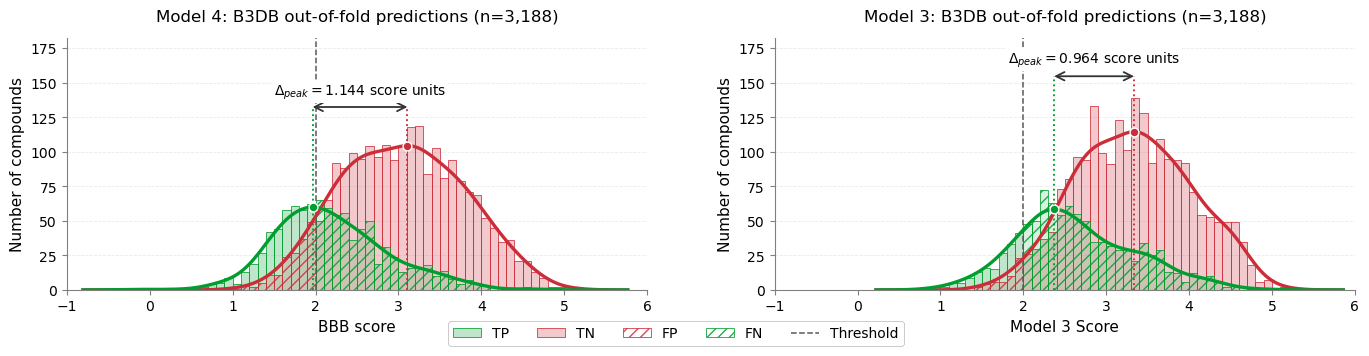

In [8]:
from matplotlib.colors import to_rgba
from scipy.stats import gaussian_kde


def plot_score_peaks(
    scores,
    labels,
    title='',
    threshold=2.,
    binwidth=.1,
    bandwidth=.20,
    ax=None,
):
    scores = np.asarray(scores, float).ravel()
    labels = np.asarray(labels).ravel()

    if scores.shape != labels.shape:
        raise ValueError(
            'Scores and labels must align molecule by molecule'
        )

    if (
        not np.isfinite(scores).all()
        or not np.isin(labels, [0, 1]).all()
    ):
        raise ValueError(
            'Need finite scores and labels 0/1; '
            'no rows are automatically removed'
        )

    class0 = scores[labels == 0]
    class1 = scores[labels == 1]

    if any(
        len(c) < 2 or np.std(c, ddof=1) == 0
        for c in [class0, class1]
    ):
        raise ValueError(
            'Each class needs at least two scores and nonzero variance'
        )

    # Compute densities and peaks using the full distributions.
    x = np.linspace(
        scores.min() - 3*bandwidth,
        scores.max() + 3*bandwidth,
        4096,
    )

    def densities(h):
        return [
            gaussian_kde(
                c, bw_method=h / np.std(c, ddof=1)
            )(x)
            for c in [class0, class1]
        ]

    kde0, kde1 = densities(bandwidth)
    peak0 = x[np.argmax(kde0)]
    peak1 = x[np.argmax(kde1)]
    gap = abs(peak0 - peak1)

    # Shared histogram bins, with the threshold on a bin boundary.
    edges = threshold + binwidth*np.arange(
        np.floor((scores.min() - threshold) / binwidth),
        np.ceil((scores.max() - threshold) / binwidth) + 2,
    )

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3.6))

    red = '#CD2D39'
    green = '#009E2F'

    # 1 = non-penetrant; predicted non-penetrant = score < threshold.
    for vals, color, hatch, label in [
        (class1[class1 < threshold], green, '', 'TP'),
        (class0[class0 >= threshold], red, '', 'TN'),
        (class0[class0 < threshold], red, '///', 'FP'),
        (class1[class1 >= threshold], green, '///', 'FN'),
    ]:
                # Draw the translucent background separately from the hatching.
        if hatch:
            ax.hist(
                vals,
                bins=edges,
                facecolor=to_rgba(color, .15),
                edgecolor='none',
                linewidth=0,
                zorder=2,
            )

        ax.hist(
            vals,
            bins=edges,
            facecolor='none' if hatch else to_rgba(color, .25),
            edgecolor=to_rgba(color, .85),
            linewidth=.65,
            hatch=hatch,
            label=label,
            zorder=2,
        )

    # KDE outlines scaled to the histogram's count axis.
    for density, c, peak, color in [
        (kde0, class0, peak0, red),
        (kde1, class1, peak1, green),
    ]:
        curve = density * len(c) * binwidth
        ax.plot(
            x, curve,
            color=color,
            lw=2.4,
            zorder=5,
        )
        ax.scatter(
            peak,
            curve[np.argmax(density)],
            color=color,
            edgecolor='white',
            s=40,
            zorder=6,
        )

    ax.axvline(
        threshold,
        color='.35',
        ls='--',
        lw=1.1,
        label='Threshold',
        zorder=3,
    )

    # Vertical peak guides, connecting arrow, and distance above.
    ymax = ax.get_ylim()[1]
    arrow_y = ymax * 1.06
    ax.set_ylim(0, ymax * 1.25)

    for peak, color in [(peak0, red), (peak1, green)]:
        ax.vlines(
            peak, 0, arrow_y,
            colors=color,
            linestyles=':',
            linewidth=1.35,
            zorder=4,
        )

    ax.annotate(
        '',
        xy=(peak0, arrow_y),
        xytext=(peak1, arrow_y),
        zorder=7,
        arrowprops=dict(
            arrowstyle='<->',
            color='.2',
            lw=1.3,
            shrinkA=0,
            shrinkB=0,
        ),
    )
    ax.text(
        (peak0 + peak1) / 2,
        arrow_y + .035*ymax,
        rf'$\Delta_{{peak}}={gap:.3f}$ score units',
        ha='center',
        va='bottom',
        fontsize=10,
        zorder=7,
        bbox=dict(
            facecolor='white',
            edgecolor='none',
            pad=1.5,
        ),
    )

    ax.set(
        xlabel='BBB score',
        ylabel='Number of compounds',
        xlim=(-1, 6),
        facecolor='white',
    )
    ax.set_xticks(np.arange(-1, 7))
    ax.set_title(title, fontsize=12, pad=12)

    ax.spines[['top', 'right']].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color('.5')

    ax.tick_params(labelsize=10, color='.5')
    ax.xaxis.label.set_size(11)
    ax.yaxis.label.set_size(11)
    ax.grid(False)
    ax.grid(axis='y', color='.92', linewidth=.6)
    ax.set_axisbelow(True)

    # Bandwidth sensitivity; these are not confidence intervals.
    rows = []
    for factor in [.75, 1., 1.25]:
        d0, d1 = (
            (kde0, kde1)
            if factor == 1
            else densities(bandwidth * factor)
        )

        p0 = x[np.argmax(d0)]
        p1 = x[np.argmax(d1)]

        rows.append({
            'bandwidth_score': bandwidth * factor,
            'n_penetrant': len(class0),
            'n_nonpenetrant': len(class1),
            'peak_penetrant': p0,
            'peak_nonpenetrant': p1,
            'peak_gap_score': abs(p0 - p1),
            'peak_gap_logBB': abs(p0 - p1) * 4.5 / 6,
        })

    return ax, pd.DataFrame(rows)


# Uses the existing MODELS definitions from the six-panel figure.
models_by_number = {
    model['number']: model
    for model in MODELS
}

fig_s1, axes_s1 = plt.subplots(
    1, 2,
    figsize=(14.0, 3.6),
    layout='none',
)
fig_s1.patch.set_facecolor('white')
fig_s1.subplots_adjust(
    left=.065,
    right=.985,
    bottom=.20,
    top=.90,
    wspace=.22,
)

all_peak_results = []

for ax, model_number in zip(axes_s1, [4, 3]):
    model = models_by_number[model_number]
    model_name = model['name']

    frame = pd.read_csv(model['oof_path'], low_memory=False)
    frame = frame.loc[frame.model.eq(model_name)].copy()

    if (
        frame.empty
        or frame.sample_id.isna().any()
        or frame.sample_id.duplicated().any()
    ):
        raise ValueError(
            f'{model_name}: need exactly one B3DB prediction per compound'
        )

    predicted_logbb = pd.to_numeric(
        frame['predicted_logBB'], errors='raise'
    ).to_numpy(float)

    labels = pd.to_numeric(
        frame['bbb_class'], errors='raise'
    ).to_numpy()

    scores = (predicted_logbb + 2.5) / 4.5 * 6

    _, peak_results = plot_score_peaks(
        scores,
        labels,
        title=(
            f'Model {model_number}: B3DB out-of-fold predictions '
            f'(n={len(frame):,})'
        ),
        threshold=2.,
        binwidth=.1,
        bandwidth=.20,
        ax=ax,
    )

    peak_results.insert(0, 'model', model_name)
    peak_results.insert(0, 'model_number', model_number)
    peak_results.insert(0, 'variant', VARIANT)
    all_peak_results.append(peak_results)

# Set identical limits AFTER plotting both panels.
# The common upper limit includes space for both peak annotations.
common_ymax = max(ax.get_ylim()[1] for ax in axes_s1)

for ax in axes_s1:
    ax.set_xlim(-1, 6)
    ax.set_ylim(0, common_ymax)
    ax.set_xticks(np.arange(-1, 7))

# One shared legend at the bottom center.
handles, labels = axes_s1[0].get_legend_handles_labels()
legend = fig_s1.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(.5, .025),
    ncol=5,
    fontsize=10,
    frameon=True,
    facecolor='white',
    edgecolor='.7',
)
legend.get_frame().set_linewidth(.6)

peak_results = pd.concat(all_peak_results, ignore_index=True)

output = Path('./results/score_peak_separation')
output.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

axes_s1[1].set_xlabel('Model 3 Score', fontsize=11)

fig_s1.savefig(
    FIGURE_DIR / 'figure_s1.png',
    dpi=1200,
    bbox_inches='tight',
)
fig_s1.savefig(
    FIGURE_DIR / 'figure_s1.svg',
    dpi=1200,
    bbox_inches='tight',
)
peak_results.to_csv(
    output / 'figure_s1_peak_separation.csv',
    index=False,
)

print(peak_results.round(4).to_string(index=False))
plt.show()

Model 3: 850/3,188 incorrectly classified
Model 4: 727/3,188 incorrectly classified
Model 5: 897/3,188 incorrectly classified


,bbb_class,class,n_compounds,n_folds,M3_mean_fold_MAE,M4_mean_fold_MAE,delta_MAE_M4_minus_M3,ci_low,ci_high,p_permutation,n_resamples,p_holm
0,0,Penetrant,680,5,0.314398,0.378947,0.064548,0.048661,0.080447,0.0001,10000,0.0002
1,1,Non-penetrant,87,5,0.660971,0.528595,-0.132376,-0.175054,-0.091964,0.0001,10000,0.0002


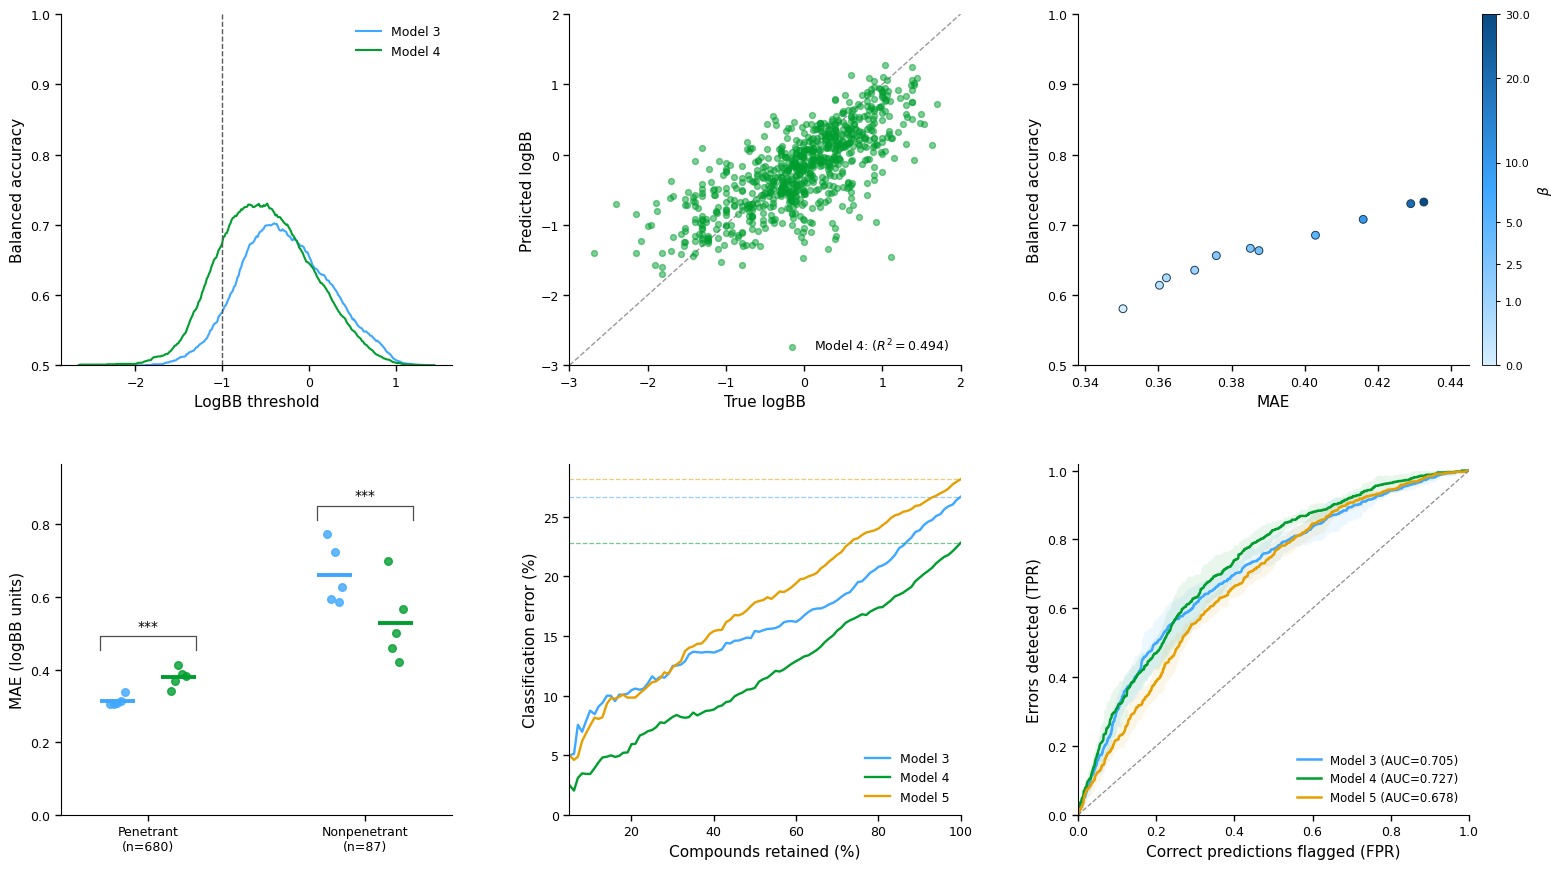

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, r2_score, roc_auc_score, roc_curve
from matplotlib.colors import LinearSegmentedColormap, PowerNorm

INPUT_CSV = "./random_outerfolds/all_model_results_main/all_models_predictions.csv"
BETA_CSV = "./results/beta_sensitivity_final_reference/custom_mtl_beta_sensitivity_plot_data.csv"
REGRESSION_METRIC = "mae"
REGRESSION_MODEL = "custom_mtl_bab"  # Model shown in panel b.
MARGIN = -1.0
BLUE, GREEN, ORANGE = "#3EA7FF", "#009E2F", "#E69F00"

FIGSIZE = (16, 9)
N_RESAMPLES = 10000
SEED = 42
SHOW_ROC_SD = True

bottom_models = {
    "lightgbm_mse_regression": ("Model 3", BLUE), # : MSE
    "custom_mtl_bab": ("Model 4", GREEN), # : Custom loss
    "lightgbm_mse_regression_threshold": ("Model 5", ORANGE), # : Tuned MSE
}
regression_models = ["lightgbm_mse_regression", "custom_mtl_bab"]

fig1_data = pd.read_csv(
    INPUT_CSV,
    usecols=["model", "row_index", "outer_fold", "true_logBB",
             "predicted_logBB", "bbb_class", "classification_threshold"],
    low_memory=False,
).drop_duplicates()

for col in ["outer_fold", "true_logBB", "predicted_logBB",
            "bbb_class", "classification_threshold"]:
    fig1_data[col] = pd.to_numeric(fig1_data[col], errors="coerce")

missing = set(bottom_models) - set(fig1_data["model"])
if missing:
    raise ValueError(f"Missing models: {sorted(missing)}")

beta_data = pd.read_csv(BETA_CSV).sort_values("beta")
reg_label = REGRESSION_METRIC.upper()

# Risk–coverage and error-detection ROC calculations.
coverage_grid = np.linspace(0.05, 1, 96)
mean_fpr = np.linspace(0, 1, 1001)
risk_rows, auc_rows, roc_by_model, reference = [], [], {}, None

for model, (label, color) in bottom_models.items():
    g = fig1_data.loc[fig1_data["model"].eq(model)].copy()
    if g["row_index"].isna().any() or g["row_index"].duplicated().any():
        raise ValueError(f"{model}: expected one OOF prediction per row_index.")

    identities = g.set_index("row_index")[["outer_fold", "bbb_class", "true_logBB"]].sort_index()
    if reference is None:
        reference = identities
    else:
        pd.testing.assert_frame_equal(identities, reference, check_dtype=False)

    pred = g["predicted_logBB"].to_numpy(float)
    threshold = g["classification_threshold"].to_numpy(float) if model.endswith("_threshold") else MARGIN

    if not np.isfinite(pred).all() or not np.isfinite(threshold).all():
        raise ValueError(f"{model}: missing/nonfinite predictions or thresholds.")
    if not g["bbb_class"].isin([0, 1]).all() or g["outer_fold"].isna().any():
        raise ValueError(f"{model}: invalid classes or missing fold assignments.")

    g["distance"] = np.abs(pred - threshold)
    g["error"] = (pred < threshold).astype(int) != g["bbb_class"].to_numpy(int)
    print(f"{label}: {g['error'].sum():,}/{len(g):,} incorrectly classified")

    ranked, fold_tprs = [], []
    for fold, h in g.groupby("outer_fold"):
        ranked.append(
            h.sample(frac=1, random_state=SEED)
             .sort_values("distance", ascending=False, kind="stable")
        )

        if h["error"].nunique() != 2:
            raise ValueError(f"{model}, fold {fold}: error ROC requires correct and incorrect predictions.")

        error_score = -h["distance"].to_numpy()
        fpr, tpr, _ = roc_curve(h["error"], error_score)
        interpolated_tpr = np.interp(mean_fpr, fpr, tpr)
        interpolated_tpr[0], interpolated_tpr[-1] = 0.0, 1.0
        fold_tprs.append(interpolated_tpr)
        auc_rows.append({
            "model": model, "outer_fold": fold,
            "auc": roc_auc_score(h["error"], error_score),
        })

    roc_by_model[model] = np.asarray(fold_tprs)

    for fraction in coverage_grid:
        kept = pd.concat([h.iloc[:int(np.ceil(fraction * len(h)))] for h in ranked])
        risk_rows.append({
            "model": model,
            "coverage": len(kept) / len(g),
            "error_rate": kept["error"].mean(),
        })

fig1_risk = pd.DataFrame(risk_rows)
fig1_auc = pd.DataFrame(auc_rows)
fold_values = sorted(fig1_auc["outer_fold"].unique())
jitter = dict(zip(fold_values, np.linspace(-0.035, 0.035, len(fold_values))))

# Regression MAE by observed BBB class, using measured logBB only.
measured = fig1_data.loc[
    fig1_data["model"].isin(regression_models) & np.isfinite(fig1_data["true_logBB"])
].copy()
measured["absolute_error"] = (measured["predicted_logBB"] - measured["true_logBB"]).abs()
fig1_mae = measured.groupby(
    ["model", "outer_fold", "bbb_class"], as_index=False
)["absolute_error"].mean()
class_counts = measured.loc[
    measured["model"].eq(regression_models[0])
].groupby("bbb_class").size()

# Paired tests of mean-fold MAE differences.
def paired_mae_test(blocks, rng, n_resamples):
    observed = np.mean([d.mean() for d in blocks])
    boot, null = np.zeros(n_resamples), np.zeros(n_resamples)

    for d in blocks:
        boot += rng.choice(d, size=(n_resamples, len(d)), replace=True).mean(axis=1)
        signs = rng.choice([-1.0, 1.0], size=(n_resamples, len(d)))
        null += (signs * d).mean(axis=1)

    boot /= len(blocks)
    null /= len(blocks)
    ci_low, ci_high = np.quantile(boot, [0.025, 0.975])
    p = (1 + np.count_nonzero(np.abs(null) >= abs(observed) - 1e-12)) / (n_resamples + 1)
    return observed, ci_low, ci_high, p

paired_errors = measured.pivot(
    index=["row_index", "outer_fold", "bbb_class"],
    columns="model", values="absolute_error",
).reindex(columns=regression_models)

if paired_errors.isna().any().any():
    raise ValueError("MAE comparisons require matched measured compounds for both models.")

paired_errors["delta"] = paired_errors["custom_mtl_bab"] - paired_errors["lightgbm_mse_regression"]
rng = np.random.default_rng(SEED)
stat_rows = []

for cls, class_name in [(0, "Penetrant"), (1, "Non-penetrant")]:
    h = paired_errors.xs(cls, level="bbb_class")
    blocks = [part["delta"].to_numpy() for _, part in h.groupby(level="outer_fold")]
    delta, ci_low, ci_high, p = paired_mae_test(blocks, rng, N_RESAMPLES)
    means = h.groupby(level="outer_fold")[regression_models].mean().mean()

    stat_rows.append({
        "bbb_class": cls, "class": class_name,
        "n_compounds": len(h), "n_folds": len(blocks),
        "M3_mean_fold_MAE": means["lightgbm_mse_regression"],
        "M4_mean_fold_MAE": means["custom_mtl_bab"],
        "delta_MAE_M4_minus_M3": delta,
        "ci_low": ci_low, "ci_high": ci_high,
        "p_permutation": p, "n_resamples": N_RESAMPLES,
    })

mae_stats = pd.DataFrame(stat_rows)

# Holm adjustment across the two class-specific comparisons.
p_values = mae_stats["p_permutation"].to_numpy()
order = np.argsort(p_values)
adjusted = np.empty(len(p_values))
adjusted[order] = np.minimum(
    1.0, np.maximum.accumulate((len(p_values) - np.arange(len(p_values))) * p_values[order])
)
mae_stats["p_holm"] = adjusted
mae_stats.to_csv("figure_1_mae_statistics.csv", index=False)
display(mae_stats.round(6))

# Manual layout.
fig1, fig1_axes = plt.subplots(2, 3, figsize=FIGSIZE, layout="none")
fig1.subplots_adjust(
    left=0.07, right=0.95, bottom=0.08, top=0.97,
    wspace=0.30, hspace=0.28,
)

# a: Balanced accuracy threshold sweep.
ax = fig1_axes[0, 0]
sweep_data = fig1_data.loc[fig1_data["model"].isin(regression_models)]
threshold_grid = np.linspace(
    sweep_data["predicted_logBB"].min() - 1e-6,
    sweep_data["predicted_logBB"].max() + 1e-6, 301,
)

for model in regression_models:
    label, color = bottom_models[model]
    h = sweep_data.loc[sweep_data["model"].eq(model)]
    y = h["bbb_class"].to_numpy(int)
    scores = h["predicted_logBB"].to_numpy()
    values = [balanced_accuracy_score(y, (scores < threshold).astype(int)) for threshold in threshold_grid]
    ax.plot(threshold_grid, values, color=color, lw=1.5, label=label)

ax.axvline(MARGIN, color="0.35", ls="--", lw=1)
ax.set(xlabel="LogBB threshold", ylabel="Balanced accuracy", ylim=(0.5, 1.0))
ax.legend(frameon=False, fontsize=9, loc="upper right")

# b: Measured versus predicted logBB for the explicitly selected model.
ax = fig1_axes[0, 1]
reg_data = fig1_data.loc[
    fig1_data["model"].eq(REGRESSION_MODEL) & np.isfinite(fig1_data["true_logBB"])
]
reg_true = reg_data["true_logBB"].to_numpy(float)
reg_pred = reg_data["predicted_logBB"].to_numpy(float)
reg_model_label, reg_color = bottom_models[REGRESSION_MODEL]
reg_r2 = r2_score(reg_true, reg_pred)

ax.plot([-3, 2], [-3, 2], color="0.6", ls="--", lw=1, zorder=1)
ax.scatter(reg_true, reg_pred, color=reg_color, alpha=0.5, s=18, label=rf"Model 4: $(R^2 = {reg_r2:.3f})$", zorder=2) # reg_model_label
# ax.text(
#     0.3, 0.95, rf"$R^2 = {reg_r2:.3f}$",
#     transform=ax.transAxes, ha="right", va="top", fontsize=10,
#     bbox=dict(boxstyle="round,pad=0.3", facecolor="none", edgecolor="0.6", linewidth=0.8),
# )
ax.set(xlabel="True logBB", ylabel="Predicted logBB", xlim=(-3, 2), ylim=(-3, 2))
ax.legend(frameon=False, fontsize=9, loc="lower right")

# c: Beta sweep.
ax = fig1_axes[0, 2]
beta_values = beta_data["beta"].to_numpy(float)
beta_accuracy = beta_data["balanced_accuracy_mean"].to_numpy(float)
beta_regression = beta_data[f"{REGRESSION_METRIC}_mean"].to_numpy(float)
beta_cmap = LinearSegmentedColormap.from_list("beta_blue", ["#D6EEFF", "#3EA7FF", "#084B83"])

points = ax.scatter(
    beta_regression, beta_accuracy, c=beta_values, cmap=beta_cmap,
    norm=PowerNorm(gamma=0.5, vmin=0, vmax=beta_values.max()),
    s=32, edgecolors="#163A59", linewidths=0.7, zorder=3,
)
ax.set(xlabel=f"{reg_label}", ylabel="Balanced accuracy", ylim=(0.5, 1.0))
ax.margins(x=0.15)

pos = ax.get_position()
cax = fig1.add_axes([pos.x1 + 0.008, pos.y0, 0.009, pos.height])
cbar = fig1.colorbar(points, cax=cax)
cbar.set_label(r"$\beta$", fontsize=10)
cbar.ax.tick_params(labelsize=8, length=3)
cbar.outline.set_linewidth(0.6)
cbar.set_ticks([0, 1, 2.5, 5, 10, 20, 30])

# d: Class-specific MAE with significance stars.
ax = fig1_axes[1, 0]
for model, offset in zip(regression_models, [-0.14, 0.14]):
    color = bottom_models[model][1]
    for cls in [0, 1]:
        h = fig1_mae.loc[fig1_mae["model"].eq(model) & fig1_mae["bbb_class"].eq(cls)]
        x = cls + offset
        ax.scatter(x + h["outer_fold"].map(jitter), h["absolute_error"],
                   s=30, color=color, alpha=0.8, zorder=3)
        ax.hlines(h["absolute_error"].mean(), x - 0.08, x + 0.08,
                  color=color, lw=2.8, zorder=4)

mae_max = fig1_mae["absolute_error"].max()
gap = max(0.01, 0.05 * mae_max)

for cls in [0, 1]:
    p = float(mae_stats.loc[mae_stats["bbb_class"].eq(cls), "p_holm"].iloc[0])
    stars = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
    height = fig1_mae.loc[fig1_mae["bbb_class"].eq(cls), "absolute_error"].max() + gap
    ax.plot(
        [cls - 0.22, cls - 0.22, cls + 0.22, cls + 0.22],
        [height, height + gap, height + gap, height],
        color="0.3", lw=0.9,
    )
    ax.text(cls, height + 1.25 * gap, stars, ha="center", va="bottom", fontsize=10)

ax.set_xticks([0, 1], [
    f"Penetrant\n(n={class_counts.get(0, 0):,})",
    f"Nonpenetrant\n(n={class_counts.get(1, 0):,})",
])
ax.set(ylabel="MAE (logBB units)", xlim=(-0.4, 1.4), ylim=(0, mae_max + 5 * gap))

# e: Overall risk–coverage.
ax = fig1_axes[1, 1]
for model, (label, color) in bottom_models.items():
    curve = fig1_risk.loc[fig1_risk["model"].eq(model)]
    ax.plot(100 * curve["coverage"], 100 * curve["error_rate"], color=color, lw=1.7, label=label)
    ax.axhline(100 * curve["error_rate"].iloc[-1], color=color, ls="--", lw=0.9, alpha=0.55)

ax.set(xlabel="Compounds retained (%)", ylabel="Classification error (%)", xlim=(5, 100))
ax.set_ylim(bottom=0)
ax.legend(frameon=False, fontsize=9, loc="lower right")

# f: Mean error-detection ROC curves.
ax = fig1_axes[1, 2]
for model, (label, color) in bottom_models.items():
    tprs = roc_by_model[model]
    mean_tpr = tprs.mean(axis=0)
    mean_auc = fig1_auc.loc[fig1_auc["model"].eq(model), "auc"].mean()

    if SHOW_ROC_SD:
        sd_tpr = tprs.std(axis=0, ddof=1 if len(tprs) > 1 else 0)
        ax.fill_between(
            mean_fpr, np.clip(mean_tpr - sd_tpr, 0, 1), np.clip(mean_tpr + sd_tpr, 0, 1),
            color=color, alpha=0.09, linewidth=0,
        )

    ax.plot(mean_fpr, mean_tpr, color=color, lw=1.8, label=f"{label} (AUC={mean_auc:.3f})")

ax.plot([0, 1], [0, 1], color="0.55", ls="--", lw=0.9)
ax.set(
    xlabel="Correct predictions flagged (FPR)",
    ylabel="Errors detected (TPR)",
    xlim=(0, 1), ylim=(0, 1.02),
)
ax.legend(frameon=False, fontsize=8.5, loc="lower right")

# Formatting; no panel letters or titles.
for ax in fig1_axes.flat:
    ax.xaxis.label.set_size(11)
    ax.yaxis.label.set_size(11)
    ax.tick_params(axis="both", labelsize=9, width=1, length=4)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)

fig1.savefig("./figures/figure_1.png", dpi=1200, bbox_inches="tight")
fig1.savefig("./figures/figure_1.svg", dpi=1200, bbox_inches="tight")
plt.show()

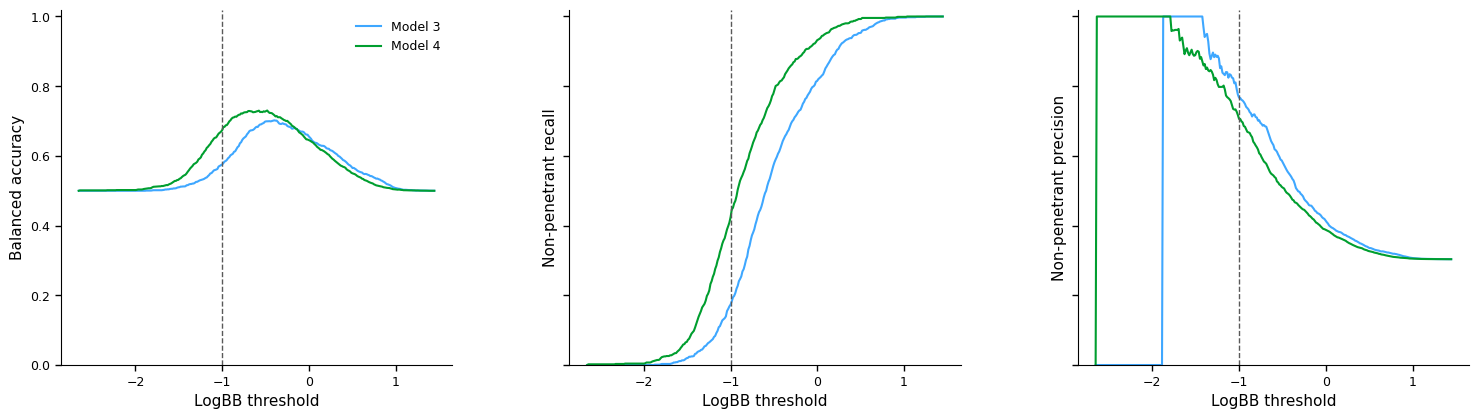

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, recall_score, precision_score

INPUT_CSV = "./random_outerfolds/all_model_results_main/all_models_predictions.csv"
MARGIN = -1.0
BLUE, GREEN = "#3EA7FF", "#009E2F"

models = {
    "lightgbm_mse_regression": ("Model 3", BLUE),
    "custom_mtl_bab": ("Model 4", GREEN),
}

data = pd.read_csv(INPUT_CSV, usecols=["model", "predicted_logBB", "bbb_class"], low_memory=False)
for col in ["predicted_logBB", "bbb_class"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

missing = set(models) - set(data["model"])
if missing:
    raise ValueError(f"Missing models: {sorted(missing)}")

data = data.loc[data["model"].isin(models)].dropna(subset=["bbb_class", "predicted_logBB"])
thresholds = np.linspace(data["predicted_logBB"].min() - 1e-6, data["predicted_logBB"].max() + 1e-6, 301)

# Control the overall figure size here.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True, layout="none")
fig.subplots_adjust(left=0.07, right=0.95, bottom=0.18, top=0.97, wspace=0.30)

for model, (label, color) in models.items():
    model_data = data.loc[data["model"].eq(model)]
    y_true = model_data["bbb_class"].to_numpy(dtype=int)
    scores = model_data["predicted_logBB"].to_numpy()

    values = []
    for threshold in thresholds:
        y_pred = (scores < threshold).astype(int)
        values.append([
            balanced_accuracy_score(y_true, y_pred),
            recall_score(y_true, y_pred, pos_label=1, zero_division=0),
            precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        ])

    for ax, curve in zip(axes, np.asarray(values).T):
        ax.plot(thresholds, curve, color=color, lw=1.5, label=label)

for ax, ylabel in zip(axes, ["Balanced accuracy", "Non-penetrant recall", "Non-penetrant precision"]):
    ax.axvline(MARGIN, color="0.35", ls="--", lw=1)
    ax.set(xlabel="LogBB threshold", ylabel=ylabel, ylim=(0, 1.02))
    ax.xaxis.label.set_size(11)
    ax.yaxis.label.set_size(11)
    ax.tick_params(axis="both", labelsize=9, width=1, length=4)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)

axes[0].legend(frameon=False, fontsize=9, loc="upper right")

fig.savefig("./figures/figure_s2.png", dpi=1200, bbox_inches="tight")
fig.savefig("./figures/figure_s2.svg", dpi=1200, bbox_inches="tight")
plt.show()

outer_fold    n    brier      ece
         0  638 0.167663 0.053114
         1  638 0.154362 0.037528
         2  638 0.168195 0.077866
         3  637 0.170714 0.059945
         4  637 0.175048 0.069363
    pooled 3188 0.167193 0.059560


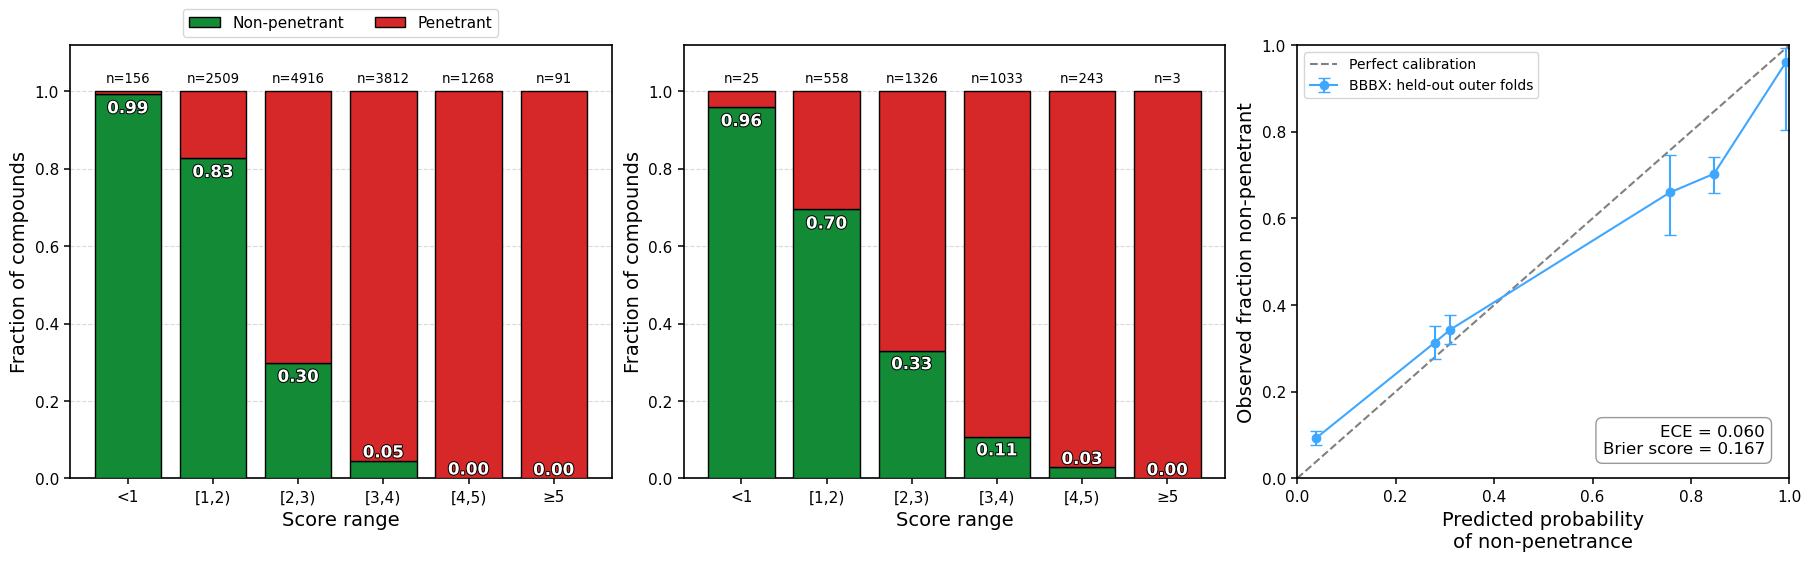

In [40]:
from pathlib import Path
import joblib
import lightgbm as lgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects

DATA_PATH = '../datasets/druglike_b3db_labelled_outerfolds.csv'
MODEL_DIR = Path('./random_outerfolds/custom_mtl_bab_results/fitted_models')
MODEL_NAME = 'custom_mtl_bab'
INNER_OOF_PATH = None  # Optional: model_outer_fold, sample_id, predicted_logBB.

data = pd.read_csv(DATA_PATH, low_memory=False)
if data.sample_id.isna().any() or data.sample_id.duplicated().any():
    raise ValueError('Need unique, nonmissing sample_id')
data['outer_fold'] = pd.to_numeric(data.outer_fold, errors='raise')
if not np.isfinite(data.outer_fold).all() or not data.outer_fold.eq(np.floor(data.outer_fold)).all():
    raise ValueError('Need finite integer outer_fold labels')
data['bbb_class'] = pd.to_numeric(data.bbb_class, errors='raise')
if not data.bbb_class.isin([0, 1]).all():
    raise ValueError('bbb_class must be 0 = penetrant, 1 = nonpenetrant')

inner = pd.read_csv(INNER_OOF_PATH, low_memory=False) if INNER_OOF_PATH is not None else None
if inner is not None:
    if 'model' in inner and not inner.model.eq(MODEL_NAME).all():
        raise ValueError('INNER_OOF_PATH must contain only MODEL_NAME')
    inner['model_outer_fold'] = pd.to_numeric(inner.model_outer_fold, errors='raise')

def score_bins(pred):
    score = (np.asarray(pred, dtype=float) + 2.5) / 4.5 * 6
    if not np.isfinite(score).all():
        raise ValueError('Nonfinite prediction; no rows were discarded')
    # Six bins with open outer ends: all predictions are included.
    return np.searchsorted(np.arange(1, 6), score, side='right')

def fit_mapping(pred, y):
    ids, y = score_bins(pred), np.asarray(y, dtype=float)
    counts = np.bincount(ids, minlength=6)
    positives = np.bincount(ids, weights=y, minlength=6)
    probabilities = np.divide(positives, counts, out=np.full(6, y.mean()), where=counts > 0)
    return probabilities, counts

def composition(frame):
    ids = score_bins(frame.predicted_logBB.to_numpy(float))
    counts = np.bincount(ids, minlength=6)
    positives = np.bincount(ids, weights=frame.bbb_class.to_numpy(float), minlength=6)
    fractions = np.divide(positives, counts, out=np.full(6, np.nan), where=counts > 0)
    return fractions, counts

def calibration_table(frame):
    p, y = frame.p_nonpen.to_numpy(float), frame.bbb_class.to_numpy(float)
    ids = np.searchsorted(np.linspace(0, 1, 11)[1:-1], p, side='right')
    rows, z = [], 1.959963984540054
    for b in range(10):
        mask = ids == b
        if not mask.any():
            continue
        n, observed = int(mask.sum()), float(y[mask].mean())
        center = (observed + z*z/(2*n)) / (1 + z*z/n)
        half = z*np.sqrt(observed*(1-observed)/n + z*z/(4*n*n)) / (1 + z*z/n)
        rows.append({
            'probability_bin': b, 'n': n, 'mean_probability': p[mask].mean(),
            'observed_nonpenetrant': observed,
            'ci_low': max(0, center-half), 'ci_high': min(1, center+half),
        })
    return pd.DataFrame(rows)

training_parts, testing_parts, mappings = [], [], []
for fold in sorted(data.outer_fold.unique()):
    training = data.loc[data.outer_fold != fold]
    testing = data.loc[data.outer_fold == fold]
    if training.empty or testing.empty:
        raise ValueError('Need nonempty training and test partitions')

    stem = f'{MODEL_NAME}_outer_{int(fold)}'
    model = lgb.Booster(model_file=str(MODEL_DIR / f'{stem}.txt'))
    prep = joblib.load(MODEL_DIR / f'{stem}_preprocessor.joblib')
    if prep.get('imputer') is not None:
        raise ValueError('Use the matching no-imputation model')
    features = list(prep['feature_names'])
    if len(features) != model.num_feature() or len(features) != len(set(features)):
        raise ValueError('Model and descriptor list disagree')

    def predict(frame):
        X = frame[features].apply(pd.to_numeric, errors='raise').to_numpy(float)
        prediction = np.asarray(model.predict(X), dtype=float).reshape(-1)
        if len(prediction) != len(frame) or not np.isfinite(prediction).all():
            raise ValueError('Invalid predictions; no rows were discarded')
        return prediction

    train_pred, test_pred = predict(training), predict(testing)

    train_part = training[['sample_id', 'outer_fold', 'bbb_class']].copy()
    train_part['model_outer_fold'] = int(fold)
    train_part['predicted_logBB'] = train_pred
    training_parts.append(train_part)

    if inner is None:
        calibration_pred = train_pred
        source = 'outer_training_in_sample'
    else:
        # Must be inner-held-out scores generated within this outer-training partition.
        c = inner.loc[inner.model_outer_fold.eq(fold)]
        if c.sample_id.isna().any() or c.sample_id.duplicated().any():
            raise ValueError(f'Fold {fold}: duplicate/missing calibration IDs')
        if set(c.sample_id) != set(training.sample_id):
            raise ValueError(f'Fold {fold}: inner OOF IDs must match training IDs exactly')
        c = c.set_index('sample_id').loc[training.sample_id]
        calibration_pred = c.predicted_logBB.to_numpy(float)
        source = 'inner_oof'

    probabilities, counts = fit_mapping(calibration_pred, training.bbb_class.to_numpy())
    part = testing[['sample_id', 'outer_fold', 'bbb_class']].copy()
    part['predicted_logBB'] = test_pred
    part['p_nonpen'] = probabilities[score_bins(test_pred)]
    part['mapping_source'] = source
    testing_parts.append(part)

    mappings.extend({
        'outer_fold': int(fold), 'score_bin': b,
        'n_calibration': int(counts[b]), 'p_nonpen': probabilities[b],
        'empty_bin_fallback': bool(counts[b] == 0), 'mapping_source': source,
    } for b in range(6))

train_predictions = pd.concat(training_parts, ignore_index=True)
oof = pd.concat(testing_parts, ignore_index=True)
if len(oof) != len(data) or oof.sample_id.duplicated().any():
    raise ValueError('Incomplete or duplicated outer-test coverage')

metric_rows, tables = [], []
for fold, frame in [*oof.groupby('outer_fold'), ('pooled', oof)]:
    table = calibration_table(frame)
    brier = np.mean((frame.p_nonpen - frame.bbb_class)**2)
    ece = np.sum(table.n * abs(table.observed_nonpenetrant - table.mean_probability)) / len(frame)
    metric_rows.append({'outer_fold': fold, 'n': len(frame), 'brier': brier, 'ece': ece})
    tables.append(table.assign(outer_fold=fold))

fold_metrics = pd.DataFrame(metric_rows)
calibration_df = pd.concat(tables, ignore_index=True)
oof.to_csv('./results/score_calibration/calibrated_outer_predictions.csv', index=False)
pd.DataFrame(mappings).to_csv('./results/score_calibration/mapping_per_outerfold.csv', index=False)
fold_metrics.to_csv('./results/score_calibration/calibration_metrics.csv', index=False)
calibration_df.to_csv('./results/score_calibration/reliability_bins.csv', index=False)
print(fold_metrics.to_string(index=False))

train_bin_vals, train_bin_support = composition(train_predictions)
test_bin_vals, test_bin_support = composition(oof)

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5.5),
    gridspec_kw={'width_ratios': [1.10, 1.10, 1]},
    layout='constrained',
)
fig.patch.set_facecolor('white')

def plot_composition(ax, fractions, support, label_loc):
    x = np.arange(6)
    ax.bar(x, fractions, width=0.78, color='#138A36', edgecolor='black',
           linewidth=1, label='Non-penetrant', zorder=3)
    ax.bar(x, 1-fractions, bottom=fractions, width=0.78, color='#D62828', 
           edgecolor='black', linewidth=1, label='Penetrant', zorder=3)

    for i, value in enumerate(fractions):
        if np.isfinite(value):
            txt = ax.text(
                i, value - 0.04*label_loc[i], f'{value:.2f}',
                ha='center', va='center', fontsize=12,
                fontweight='bold', color='white', zorder=5,
            )
            txt.set_path_effects([
                path_effects.Stroke(linewidth=1.4, foreground='black'),
                path_effects.Normal(),
            ])
        ax.text(i, 1.015, f'n={support[i]}', ha='center', va='bottom', fontsize=9.5)

    ax.set(xlabel='Score range', ylabel='Fraction of compounds',
           ylim=(0, 1.12), yticks=np.arange(0, 1.01, 0.2))
    ax.set_xticks(x, labels=['<1', '[1,2)', '[2,3)', '[3,4)', '[4,5)', '≥5'])
    ax.grid(axis='y', linewidth=0.8, color='0.85')
    ax.set_axisbelow(True)

plot_composition(axes[0], train_bin_vals, train_bin_support, [0.95, 0.95, 0.91, -0.5, -0.5, -0.5])
plot_composition(axes[1], test_bin_vals, test_bin_support, [0.95, 0.95, 0.91, 0.91, -0.5, -0.5])
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, 1.1),
               ncol=2, frameon=True, fontsize=11)

# Third panel: pooled held-out predictions, each using its own outer-fold mapping.
pooled = calibration_df.loc[calibration_df.outer_fold.eq('pooled')].sort_values('probability_bin')
pooled_metrics = fold_metrics.loc[fold_metrics.outer_fold.eq('pooled')].iloc[0]
x = pooled.mean_probability.to_numpy(float)
obs = pooled.observed_nonpenetrant.to_numpy(float)
lo, hi = pooled.ci_low.to_numpy(float), pooled.ci_high.to_numpy(float)

ax = axes[2]
ax.plot([0, 1], [0, 1], '--', color='0.5', label='Perfect calibration')
ax.errorbar(
    x, obs, yerr=np.maximum(0, np.vstack([obs-lo, hi-obs])),
    fmt='o-', capsize=4, color='#3EA7FF', label='BBBX: held-out outer folds',
)
ax.set(xlabel='Predicted probability\nof non-penetrance',
       ylabel='Observed fraction non-penetrant', xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=10, frameon=True)
ax.text(
    0.95, 0.05, f"ECE = {pooled_metrics['ece']:.3f}\nBrier score = {pooled_metrics['brier']:.3f}",
    transform=ax.transAxes, ha='right', va='bottom', fontsize=12,
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='gray', alpha=0.8),
)

for ax in axes:
    ax.set_facecolor('white')
    ax.xaxis.label.set_size(14)
    ax.yaxis.label.set_size(14)
    ax.tick_params(axis='both', labelsize=11, width=1.1, length=4.5)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.2)

fig.savefig("./figures/figure_s3.png", dpi=1200, bbox_inches='tight')
fig.savefig("./figures/figure_s3.svg", dpi=1200, bbox_inches='tight')
plt.show()

dataset          model   n  observed_nonpenetrant    brier     ece  n_probability_bins mapping_source
Inxight custom_mtl_bab 210                    0.5 0.250673 0.12314                  10 B3DB_outer_OOF


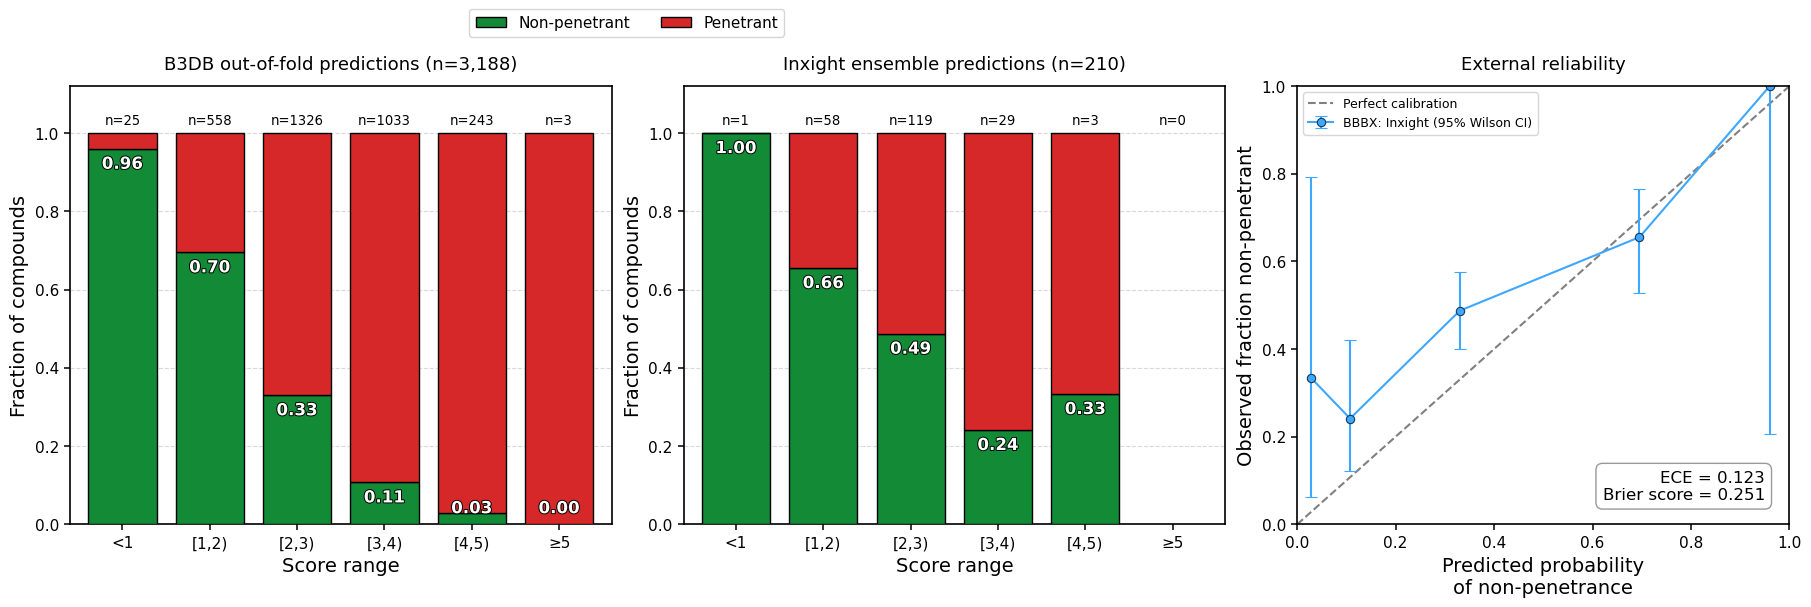

In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects

VARIANT = 'random_outerfolds'
MODEL_NAME = 'custom_mtl_bab'
OOF_PATH = Path(f'./{VARIANT}/custom_mtl_bab_results/custom_mtl_predictions.csv')
INXIGHT_PATH = Path(f'./inxight_results/{VARIANT}/all_selected_models.csv')
N_PROBABILITY_BINS = 10
SCORE_LABELS = ['<1', '[1,2)', '[2,3)', '[3,4)', '[4,5)', '≥5']
OUT = Path(f"./results/score_calibration_inxight/{VARIANT}_{MODEL_NAME}")

oof = pd.read_csv(OOF_PATH, low_memory=False)
external = pd.read_csv(INXIGHT_PATH, low_memory=False)
external = external.loc[external.model.eq(MODEL_NAME)].copy()
external = external.rename(columns={'predicted_logbb': 'predicted_logBB'})
if not oof.model.eq(MODEL_NAME).all(): raise ValueError('OOF file must contain only the chosen model')

for name, frame, id_col in [('B3DB', oof, 'sample_id'), ('Inxight', external, 'external_compound_id')]:
    if frame.empty or frame[id_col].isna().any() or frame[id_col].duplicated().any():
        raise ValueError(f'{name}: need exactly one prediction per compound')
    frame['bbb_class'] = pd.to_numeric(frame.bbb_class, errors='raise')
    frame['predicted_logBB'] = pd.to_numeric(frame.predicted_logBB, errors='raise')
    if not frame.bbb_class.isin([0, 1]).all(): raise ValueError(f'{name}: bbb_class must be 0/1')
    if not np.isfinite(frame.predicted_logBB).all(): raise ValueError(f'{name}: nonfinite predictions')

if oof.outer_fold.isna().any(): raise ValueError('Missing B3DB outer-fold labels')
if not external.n_fold_models.eq(oof.outer_fold.nunique()).all():
    raise ValueError('External predictions must be the ensemble of all outer-fold models')

def score_bins(pred):
    score = (np.asarray(pred, dtype=float) + 2.5) / 4.5 * 6
    return np.searchsorted(np.arange(1, 6), score, side='right')

def composition(frame):
    ids = score_bins(frame.predicted_logBB)
    counts = np.bincount(ids, minlength=6)
    positives = np.bincount(ids, weights=frame.bbb_class, minlength=6)
    fractions = np.divide(positives, counts, out=np.full(6, np.nan), where=counts > 0)
    return fractions, counts, positives

# Fit the mapping ONLY on B3DB out-of-fold predictions and B3DB labels.
probabilities, oof_counts, oof_positives = composition(oof)
mapping = pd.DataFrame({
    'score_bin': np.arange(6), 'score_range': SCORE_LABELS,
    'n_calibration': oof_counts, 'nonpenetrant': oof_positives.astype(int),
    'p_nonpen': probabilities,
})

# Apply the frozen mapping to the saved mean-logBB ensemble predictions.
external['score'] = (external.predicted_logBB + 2.5) / 4.5 * 6
external['score_bin'] = score_bins(external.predicted_logBB)
external['p_nonpen'] = probabilities[external.score_bin.to_numpy()]
if not np.isfinite(external.p_nonpen).all():
    raise ValueError('Inxight occupies a score bin with no B3DB calibration compounds')

# Inxight labels are used for assessment, never for fitting the mapping.
p, y = external.p_nonpen.to_numpy(float), external.bbb_class.to_numpy(float)
edges = np.linspace(0, 1, N_PROBABILITY_BINS + 1)
bin_ids = np.searchsorted(edges[1:-1], p, side='right')

rows, z = [], 1.959963984540054
for b in range(N_PROBABILITY_BINS):
    mask = bin_ids == b
    if not mask.any(): continue  # Empty plotting bins; no compounds are removed.
    n, observed = int(mask.sum()), float(y[mask].mean())
    center = (observed + z*z/(2*n)) / (1 + z*z/n)
    half = z*np.sqrt(observed*(1-observed)/n + z*z/(4*n*n)) / (1 + z*z/n)
    rows.append({
        'probability_bin': b, 'bin_left': edges[b], 'bin_right': edges[b+1],
        'n': n, 'mean_probability': float(p[mask].mean()),
        'observed_nonpenetrant': observed,
        'ci_low': max(0, center-half), 'ci_high': min(1, center+half),
    })

reliability = pd.DataFrame(rows)
brier = float(np.mean((p-y)**2))
ece = float(np.sum(reliability.n * abs(reliability.observed_nonpenetrant-reliability.mean_probability)) / len(y))
metrics = pd.DataFrame([{
    'dataset': 'Inxight', 'model': MODEL_NAME, 'n': len(y),
    'observed_nonpenetrant': y.mean(), 'brier': brier, 'ece': ece,
    'n_probability_bins': N_PROBABILITY_BINS, 'mapping_source': 'B3DB_outer_OOF',
}])
inxight_fractions, inxight_counts, _ = composition(external)

OUT.mkdir(parents=True, exist_ok=True)
mapping.to_csv(OUT / 'mapping_from_b3db_oof.csv', index=False)
external.to_csv(OUT / 'calibrated_inxight_predictions.csv', index=False)
reliability.to_csv(OUT / 'reliability_bins.csv', index=False)
metrics.to_csv(OUT / 'calibration_metrics.csv', index=False)
print(metrics.to_string(index=False))

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5.5),
    gridspec_kw={'width_ratios': [1.10, 1.10, 1]}, layout='constrained',
)
fig.patch.set_facecolor('white')

def plot_composition(ax, fractions, support, title):
    x = np.arange(6)
    ax.bar(x, fractions, width=.78, color='#138A36', edgecolor='black',
           linewidth=1, label='Non-penetrant', zorder=3)
    ax.bar(x, 1-fractions, bottom=fractions, width=.78, color='#D62828',
           edgecolor='black', linewidth=1, label='Penetrant', zorder=3)

    for i, value in enumerate(fractions):
        if np.isfinite(value):
            text = ax.text(
                i, np.clip(value-.04, .04, .96), f'{value:.2f}',
                ha='center', va='center', fontsize=12,
                fontweight='bold', color='white', zorder=5,
            )
            text.set_path_effects([
                path_effects.Stroke(linewidth=1.4, foreground='black'),
                path_effects.Normal(),
            ])
        ax.text(i, 1.015, f'n={support[i]}', ha='center', va='bottom', fontsize=9.5)

    ax.set(xlabel='Score range', ylabel='Fraction of compounds',
           xlim=(-.6, 5.6), ylim=(0, 1.12), yticks=np.arange(0, 1.01, .2))
    ax.set_xticks(x, labels=SCORE_LABELS)
    ax.set_title(title, fontsize=13, pad=12)
    ax.grid(axis='y', linewidth=.8, color='0.85')
    ax.set_axisbelow(True)

plot_composition(axes[0], probabilities, oof_counts, f'B3DB out-of-fold predictions (n={len(oof):,})')
plot_composition(axes[1], inxight_fractions, inxight_counts, f'Inxight ensemble predictions (n={len(external):,})')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.345, 1.09),
           ncol=2, frameon=True, fontsize=11)

# External reliability: mean predicted probability versus observed fraction.
ax = axes[2]
x = reliability.mean_probability.to_numpy(float)
observed = reliability.observed_nonpenetrant.to_numpy(float)
low, high = reliability.ci_low.to_numpy(float), reliability.ci_high.to_numpy(float)

ax.plot([0, 1], [0, 1], '--', color='0.5', label='Perfect calibration')
ax.errorbar(
    x, observed, yerr=np.maximum(0, np.vstack([observed-low, high-observed])),
    fmt='o-', capsize=4, color='#3EA7FF',
    markeredgecolor='#163A59', markeredgewidth=.8,
    label='BBBX: Inxight (95% Wilson CI)',
)
ax.set(xlabel='Predicted probability\nof non-penetrance',
       ylabel='Observed fraction non-penetrant', xlim=(0, 1), ylim=(0, 1))
ax.set_title('External reliability', fontsize=13, pad=12)
ax.legend(loc='upper left', fontsize=9, frameon=True)
ax.text(
    .95, .05, f'ECE = {ece:.3f}\nBrier score = {brier:.3f}',
    transform=ax.transAxes, ha='right', va='bottom', fontsize=12,
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='gray', alpha=.8),
)

for ax in axes:
    ax.set_facecolor('white')
    ax.xaxis.label.set_size(14)
    ax.yaxis.label.set_size(14)
    ax.tick_params(axis='both', labelsize=11, width=1.1, length=4.5)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.2)

fig.savefig("./figures/figure2_1.png", dpi=1200, bbox_inches='tight')
fig.savefig("./figures/figure2_1.svg", dpi=1200, bbox_inches='tight')
plt.show()

dataset                             model   n  observed_nonpenetrant   brier      ece  n_probability_bins mapping_source
Inxight lightgbm_mse_regression_threshold 210                    0.5 0.26773 0.159151                  10 B3DB_outer_OOF


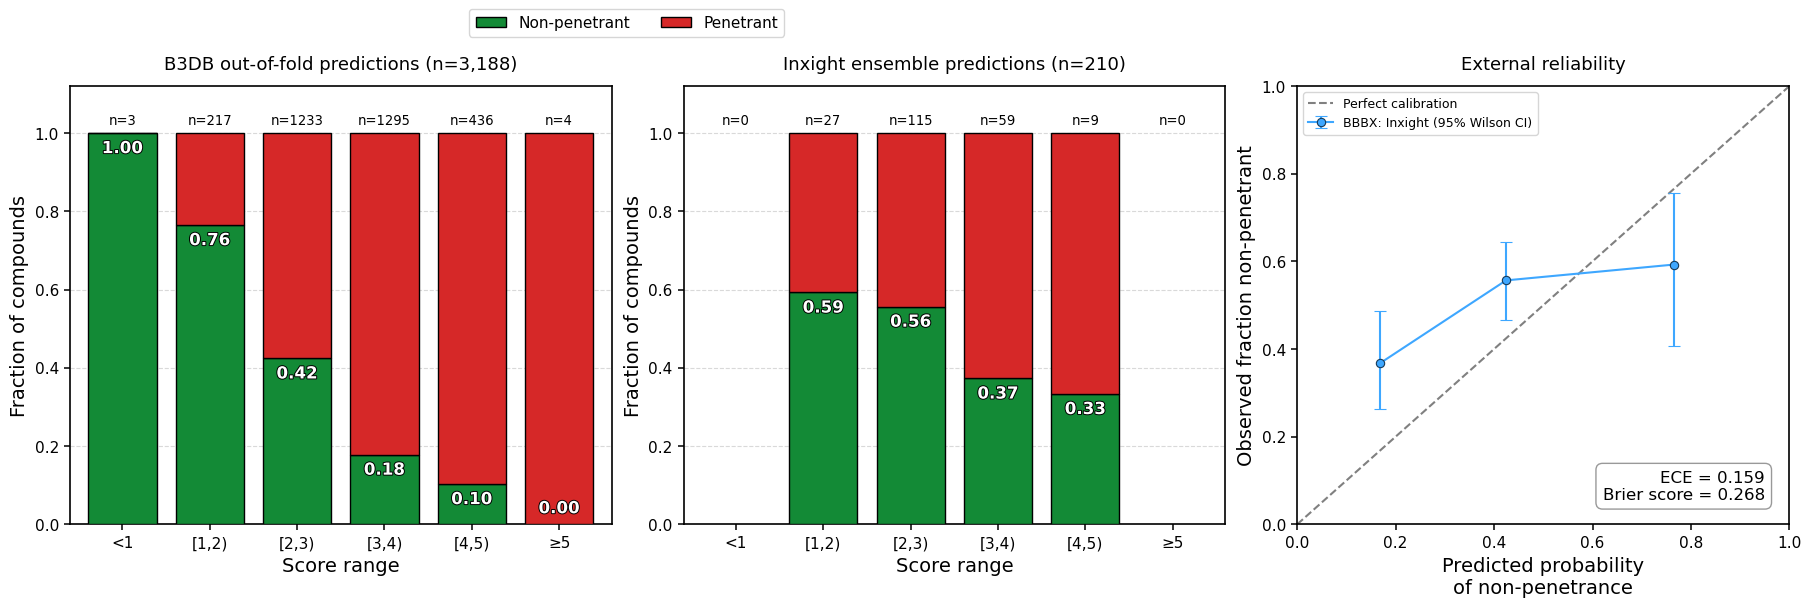

In [25]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects

VARIANT = 'random_outerfolds'
MODEL_NAME = 'lightgbm_mse_regression_threshold'
#
OOF_PATH = Path(f'./{VARIANT}/baseline_threshold_ablation_results/all_models_predictions.csv')
INXIGHT_PATH = Path(f'./inxight_results/{VARIANT}/all_selected_models.csv')
OUT = Path(f'./results/score_calibration_inxight/{VARIANT}_{MODEL_NAME}')
N_PROBABILITY_BINS = 10
SCORE_LABELS = ['<1', '[1,2)', '[2,3)', '[3,4)', '[4,5)', '≥5']

oof = pd.read_csv(OOF_PATH, low_memory=False)
oof = oof[oof.model.eq(MODEL_NAME)].copy()
external = pd.read_csv(INXIGHT_PATH, low_memory=False)
external = external.loc[external.model.eq(MODEL_NAME)].copy()
external = external.rename(columns={'predicted_logbb': 'predicted_logBB'})
if not oof.model.eq(MODEL_NAME).all(): raise ValueError('OOF file must contain only the chosen model')

for name, frame, id_col in [('B3DB', oof, 'sample_id'), ('Inxight', external, 'external_compound_id')]:
    if frame.empty or frame[id_col].isna().any() or frame[id_col].duplicated().any():
        raise ValueError(f'{name}: need exactly one prediction per compound')
    frame['bbb_class'] = pd.to_numeric(frame.bbb_class, errors='raise')
    frame['predicted_logBB'] = pd.to_numeric(frame.predicted_logBB, errors='raise')
    if not frame.bbb_class.isin([0, 1]).all(): raise ValueError(f'{name}: bbb_class must be 0/1')
    if not np.isfinite(frame.predicted_logBB).all(): raise ValueError(f'{name}: nonfinite predictions')

if oof.outer_fold.isna().any(): raise ValueError('Missing B3DB outer-fold labels')
if not external.n_fold_models.eq(oof.outer_fold.nunique()).all():
    raise ValueError('External predictions must be the ensemble of all outer-fold models')

def score_bins(pred):
    score = (np.asarray(pred, dtype=float) + 2.5) / 4.5 * 6
    return np.searchsorted(np.arange(1, 6), score, side='right')

def composition(frame):
    ids = score_bins(frame.predicted_logBB)
    counts = np.bincount(ids, minlength=6)
    positives = np.bincount(ids, weights=frame.bbb_class, minlength=6)
    fractions = np.divide(positives, counts, out=np.full(6, np.nan), where=counts > 0)
    return fractions, counts, positives

# Fit the mapping ONLY on B3DB out-of-fold predictions and B3DB labels.
probabilities, oof_counts, oof_positives = composition(oof)
mapping = pd.DataFrame({
    'score_bin': np.arange(6), 'score_range': SCORE_LABELS,
    'n_calibration': oof_counts, 'nonpenetrant': oof_positives.astype(int),
    'p_nonpen': probabilities,
})

# Apply the frozen mapping to the saved mean-logBB ensemble predictions.
external['score'] = (external.predicted_logBB + 2.5) / 4.5 * 6
external['score_bin'] = score_bins(external.predicted_logBB)
external['p_nonpen'] = probabilities[external.score_bin.to_numpy()]
if not np.isfinite(external.p_nonpen).all():
    raise ValueError('Inxight occupies a score bin with no B3DB calibration compounds')

# Inxight labels are used for assessment, never for fitting the mapping.
p, y = external.p_nonpen.to_numpy(float), external.bbb_class.to_numpy(float)
edges = np.linspace(0, 1, N_PROBABILITY_BINS + 1)
bin_ids = np.searchsorted(edges[1:-1], p, side='right')

rows, z = [], 1.959963984540054
for b in range(N_PROBABILITY_BINS):
    mask = bin_ids == b
    if not mask.any(): continue  # Empty plotting bins; no compounds are removed.
    n, observed = int(mask.sum()), float(y[mask].mean())
    center = (observed + z*z/(2*n)) / (1 + z*z/n)
    half = z*np.sqrt(observed*(1-observed)/n + z*z/(4*n*n)) / (1 + z*z/n)
    rows.append({
        'probability_bin': b, 'bin_left': edges[b], 'bin_right': edges[b+1],
        'n': n, 'mean_probability': float(p[mask].mean()),
        'observed_nonpenetrant': observed,
        'ci_low': max(0, center-half), 'ci_high': min(1, center+half),
    })

reliability = pd.DataFrame(rows)
brier = float(np.mean((p-y)**2))
ece = float(np.sum(reliability.n * abs(reliability.observed_nonpenetrant-reliability.mean_probability)) / len(y))
metrics = pd.DataFrame([{
    'dataset': 'Inxight', 'model': MODEL_NAME, 'n': len(y),
    'observed_nonpenetrant': y.mean(), 'brier': brier, 'ece': ece,
    'n_probability_bins': N_PROBABILITY_BINS, 'mapping_source': 'B3DB_outer_OOF',
}])
inxight_fractions, inxight_counts, _ = composition(external)

OUT.mkdir(parents=True, exist_ok=True)
mapping.to_csv(OUT / 'mapping_from_b3db_oof.csv', index=False)
external.to_csv(OUT / 'calibrated_inxight_predictions.csv', index=False)
reliability.to_csv(OUT / 'reliability_bins.csv', index=False)
metrics.to_csv(OUT / 'calibration_metrics.csv', index=False)
print(metrics.to_string(index=False))

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5.5),
    gridspec_kw={'width_ratios': [1.10, 1.10, 1]}, layout='constrained',
)
fig.patch.set_facecolor('white')

def plot_composition(ax, fractions, support, title):
    x = np.arange(6)
    ax.bar(x, fractions, width=.78, color='#138A36', edgecolor='black',
           linewidth=1, label='Non-penetrant', zorder=3)
    ax.bar(x, 1-fractions, bottom=fractions, width=.78, color='#D62828',
           edgecolor='black', linewidth=1, label='Penetrant', zorder=3)

    for i, value in enumerate(fractions):
        if np.isfinite(value):
            text = ax.text(
                i, np.clip(value-.04, .04, .96), f'{value:.2f}',
                ha='center', va='center', fontsize=12,
                fontweight='bold', color='white', zorder=5,
            )
            text.set_path_effects([
                path_effects.Stroke(linewidth=1.4, foreground='black'),
                path_effects.Normal(),
            ])
        ax.text(i, 1.015, f'n={support[i]}', ha='center', va='bottom', fontsize=9.5)

    ax.set(xlabel='Score range', ylabel='Fraction of compounds',
           xlim=(-.6, 5.6), ylim=(0, 1.12), yticks=np.arange(0, 1.01, .2))
    ax.set_xticks(x, labels=SCORE_LABELS)
    ax.set_title(title, fontsize=13, pad=12)
    ax.grid(axis='y', linewidth=.8, color='0.85')
    ax.set_axisbelow(True)

plot_composition(axes[0], probabilities, oof_counts, f'B3DB out-of-fold predictions (n={len(oof):,})')
plot_composition(axes[1], inxight_fractions, inxight_counts, f'Inxight ensemble predictions (n={len(external):,})')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.345, 1.09),
           ncol=2, frameon=True, fontsize=11)

# External reliability: mean predicted probability versus observed fraction.
ax = axes[2]
x = reliability.mean_probability.to_numpy(float)
observed = reliability.observed_nonpenetrant.to_numpy(float)
low, high = reliability.ci_low.to_numpy(float), reliability.ci_high.to_numpy(float)

ax.plot([0, 1], [0, 1], '--', color='0.5', label='Perfect calibration')
ax.errorbar(
    x, observed, yerr=np.maximum(0, np.vstack([observed-low, high-observed])),
    fmt='o-', capsize=4, color='#3EA7FF',
    markeredgecolor='#163A59', markeredgewidth=.8,
    label='BBBX: Inxight (95% Wilson CI)',
)
ax.set(xlabel='Predicted probability\nof non-penetrance',
       ylabel='Observed fraction non-penetrant', xlim=(0, 1), ylim=(0, 1))
ax.set_title('External reliability', fontsize=13, pad=12)
ax.legend(loc='upper left', fontsize=9, frameon=True)
ax.text(
    .95, .05, f'ECE = {ece:.3f}\nBrier score = {brier:.3f}',
    transform=ax.transAxes, ha='right', va='bottom', fontsize=12,
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='gray', alpha=.8),
)

for ax in axes:
    ax.set_facecolor('white')
    ax.xaxis.label.set_size(14)
    ax.yaxis.label.set_size(14)
    ax.tick_params(axis='both', labelsize=11, width=1.1, length=4.5)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.2)

fig.savefig('./figures/figure2_2.png', dpi=1200, bbox_inches='tight')
fig.savefig('./figures/figure2_2.svg', dpi=1200, bbox_inches='tight')
plt.show()

dataset          model   n  observed_nonpenetrant    brier     ece  n_probability_bins mapping_source
Inxight custom_mtl_bab 210                    0.5 0.250673 0.12314                  10 B3DB_outer_OOF
dataset                             model   n  observed_nonpenetrant   brier      ece  n_probability_bins mapping_source
Inxight lightgbm_mse_regression_threshold 210                    0.5 0.26773 0.159151                  10 B3DB_outer_OOF


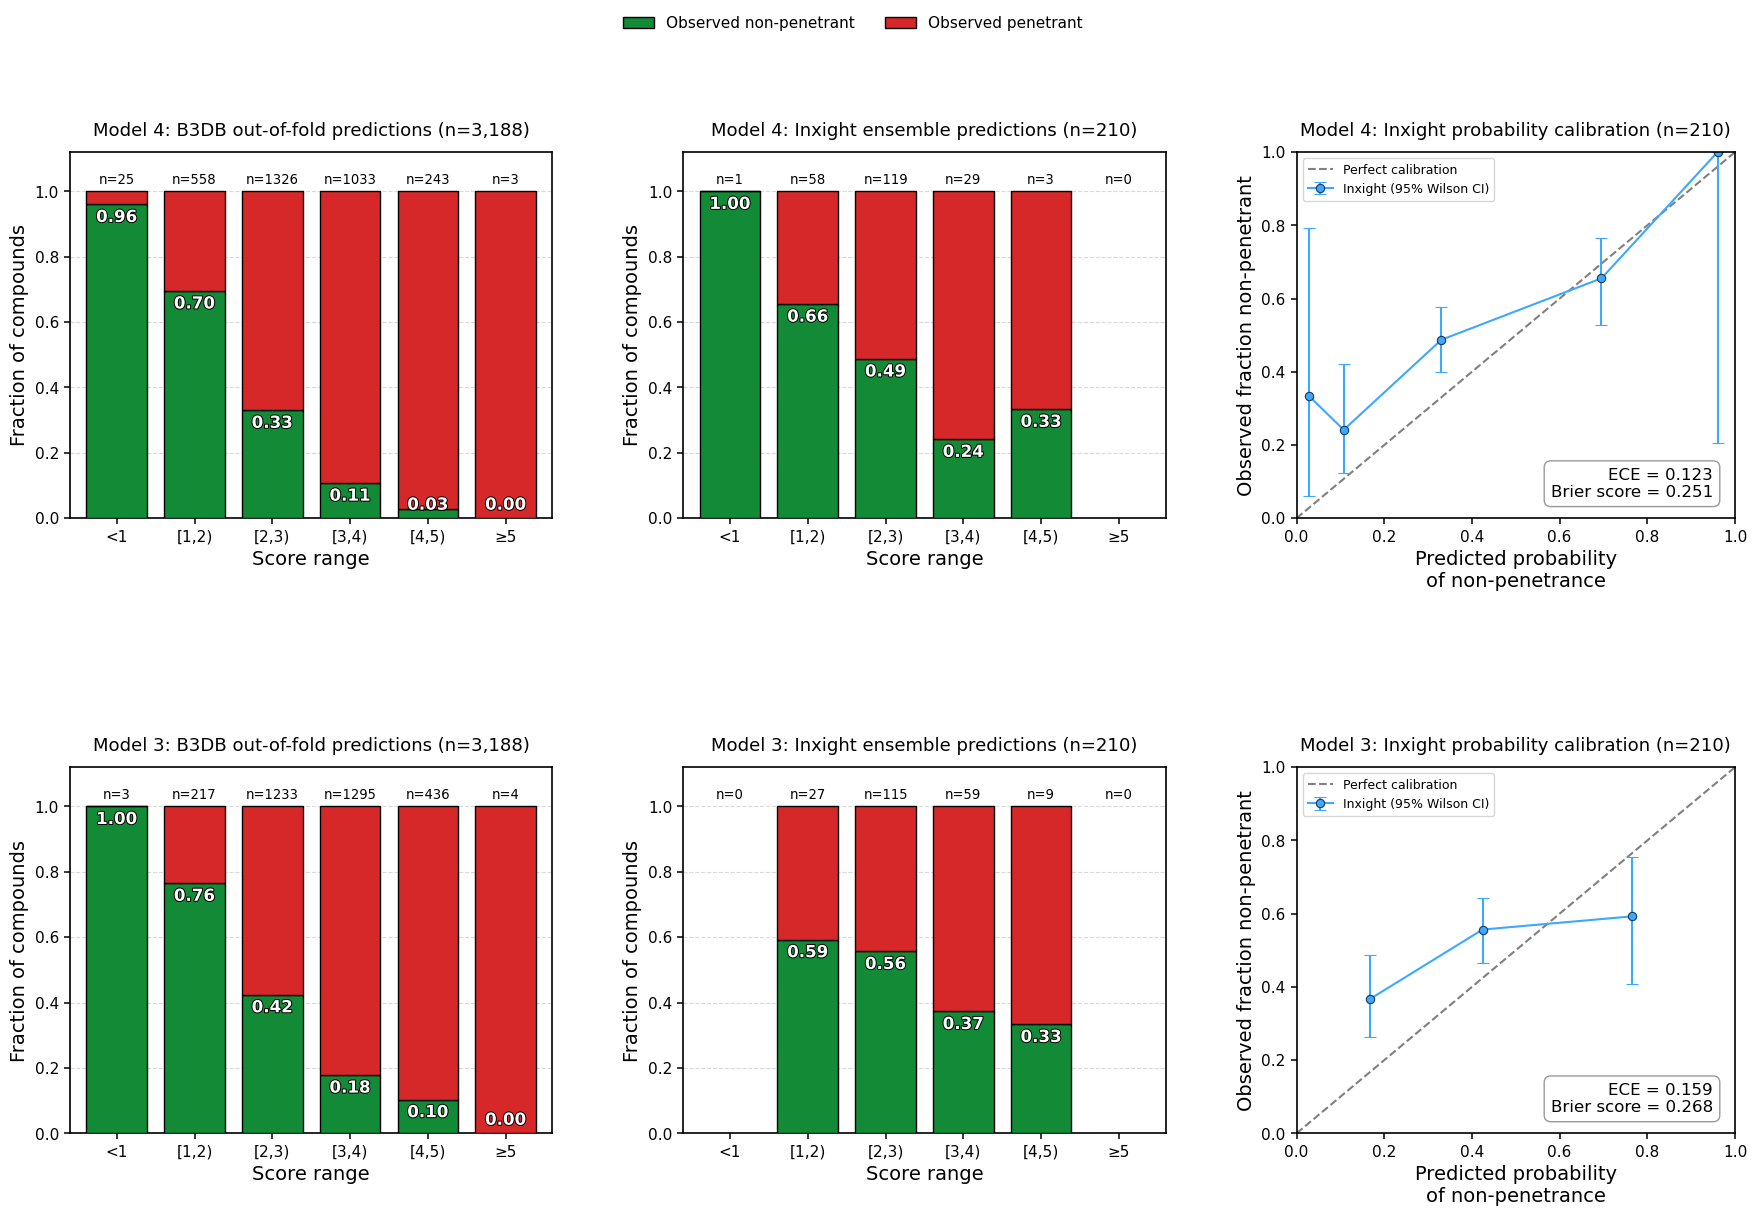

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects

VARIANT = 'random_outerfolds'
INXIGHT_PATH = Path(
    f'./inxight_results/{VARIANT}/all_selected_models.csv'
)
N_PROBABILITY_BINS = 10
SCORE_LABELS = ['<1', '[1,2)', '[2,3)', '[3,4)', '[4,5)', '≥5']

# Order determines the figure rows.
MODELS = [
    {
        'number': 4,
        'name': 'custom_mtl_bab',
        'oof_path': Path(
            f'./{VARIANT}/custom_mtl_bab_results/'
            'custom_mtl_predictions.csv'
        ),
    },
    {
        'number': 3,
        'name': 'lightgbm_mse_regression_threshold',
        'oof_path': Path(
            f'./{VARIANT}/baseline_threshold_ablation_results/'
            'all_models_predictions.csv'
        ),
    },
]

FIGURE_DIR = Path('./figures')
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

external_all = pd.read_csv(INXIGHT_PATH, low_memory=False)


def score_bins(pred):
    score = (np.asarray(pred, dtype=float) + 2.5) / 4.5 * 6
    return np.searchsorted(np.arange(1, 6), score, side='right')


def composition(frame):
    ids = score_bins(frame.predicted_logBB)
    counts = np.bincount(ids, minlength=6)
    positives = np.bincount(
        ids, weights=frame.bbb_class, minlength=6
    )
    fractions = np.divide(
        positives,
        counts,
        out=np.full(6, np.nan),
        where=counts > 0,
    )
    return fractions, counts, positives


def plot_composition(ax, fractions, support, title):
    x = np.arange(6)

    ax.bar(
        x, fractions,
        width=.78,
        color='#138A36',
        edgecolor='black',
        linewidth=1,
        label='Observed non-penetrant',
        zorder=3,
    )
    ax.bar(
        x, 1 - fractions,
        bottom=fractions,
        width=.78,
        color='#D62828',
        edgecolor='black',
        linewidth=1,
        label='Observed penetrant',
        zorder=3,
    )

    for i, value in enumerate(fractions):
        if np.isfinite(value):
            text = ax.text(
                i,
                np.clip(value - .04, .04, .96),
                f'{value:.2f}',
                ha='center',
                va='center',
                fontsize=12,
                fontweight='bold',
                color='white',
                zorder=5,
            )
            text.set_path_effects([
                path_effects.Stroke(
                    linewidth=1.4, foreground='black'
                ),
                path_effects.Normal(),
            ])

        ax.text(
            i, 1.015,
            f'n={support[i]}',
            ha='center',
            va='bottom',
            fontsize=9.5,
        )

    ax.set(
        xlabel='Score range',
        ylabel='Fraction of compounds',
        xlim=(-.6, 5.6),
        ylim=(0, 1.12),
        yticks=np.arange(0, 1.01, .2),
    )
    ax.set_xticks(x, labels=SCORE_LABELS)
    ax.set_title(title, fontsize=13, pad=12)
    ax.grid(axis='y', linewidth=.8, color='0.85')
    ax.set_axisbelow(True)


fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 12.5),
    gridspec_kw={'width_ratios': [1.10, 1.10, 1]},
    layout='none',
)
fig.patch.set_facecolor('white')
fig.subplots_adjust(
    left=.065,
    right=.99,
    bottom=.075,
    top=.86,
    wspace=.28,
    hspace=.68,
)

for row, model in enumerate(MODELS):
    model_name = model['name']
    model_label = f"Model {model['number']}"

    out = Path(
        f'./results/score_calibration_inxight/'
        f'{VARIANT}_{model_name}'
    )

    oof = pd.read_csv(model['oof_path'], low_memory=False)
    oof = oof.loc[oof.model.eq(model_name)].copy()

    external = external_all.loc[
        external_all.model.eq(model_name)
    ].copy()
    external = external.rename(
        columns={'predicted_logbb': 'predicted_logBB'}
    )

    for name, frame, id_col in [
        ('B3DB', oof, 'sample_id'),
        ('Inxight', external, 'external_compound_id'),
    ]:
        if (
            frame.empty
            or frame[id_col].isna().any()
            or frame[id_col].duplicated().any()
        ):
            raise ValueError(
                f'{model_name}, {name}: '
                'need exactly one prediction per compound'
            )

        frame['bbb_class'] = pd.to_numeric(
            frame.bbb_class, errors='raise'
        )
        frame['predicted_logBB'] = pd.to_numeric(
            frame.predicted_logBB, errors='raise'
        )

        if not frame.bbb_class.isin([0, 1]).all():
            raise ValueError(
                f'{model_name}, {name}: bbb_class must be 0/1'
            )

        if not np.isfinite(frame.predicted_logBB).all():
            raise ValueError(
                f'{model_name}, {name}: nonfinite predictions'
            )

    if oof.outer_fold.isna().any():
        raise ValueError(
            f'{model_name}: missing B3DB outer-fold labels'
        )

    if not external.n_fold_models.eq(
        oof.outer_fold.nunique()
    ).all():
        raise ValueError(
            f'{model_name}: external predictions must be '
            'the ensemble of all outer-fold models'
        )

    # Fit a separate mapping for each model using ONLY B3DB OOF data.
    probabilities, oof_counts, oof_positives = composition(oof)

    mapping = pd.DataFrame({
        'score_bin': np.arange(6),
        'score_range': SCORE_LABELS,
        'n_calibration': oof_counts,
        'nonpenetrant': oof_positives.astype(int),
        'p_nonpen': probabilities,
    })

    # Apply the frozen mapping to the mean-logBB ensemble predictions.
    external['score'] = (
        (external.predicted_logBB + 2.5) / 4.5 * 6
    )
    external['score_bin'] = score_bins(external.predicted_logBB)
    external['p_nonpen'] = probabilities[
        external.score_bin.to_numpy()
    ]

    if not np.isfinite(external.p_nonpen).all():
        raise ValueError(
            f'{model_name}: Inxight occupies a score bin '
            'with no B3DB calibration compounds'
        )

    # Inxight labels are used for assessment, never to fit the mapping.
    p = external.p_nonpen.to_numpy(float)
    y = external.bbb_class.to_numpy(float)

    edges = np.linspace(0, 1, N_PROBABILITY_BINS + 1)
    bin_ids = np.searchsorted(edges[1:-1], p, side='right')

    reliability_rows = []
    z = 1.959963984540054

    for b in range(N_PROBABILITY_BINS):
        mask = bin_ids == b
        if not mask.any():
            continue  # Empty plotting bins; no compounds are removed.

        n = int(mask.sum())
        observed = float(y[mask].mean())

        center = (
            (observed + z*z / (2*n))
            / (1 + z*z / n)
        )
        half = (
            z * np.sqrt(
                observed * (1 - observed) / n
                + z*z / (4*n*n)
            )
            / (1 + z*z / n)
        )

        reliability_rows.append({
            'probability_bin': b,
            'bin_left': edges[b],
            'bin_right': edges[b + 1],
            'n': n,
            'mean_probability': float(p[mask].mean()),
            'observed_nonpenetrant': observed,
            'ci_low': max(0, center - half),
            'ci_high': min(1, center + half),
        })

    reliability = pd.DataFrame(reliability_rows)

    brier = float(np.mean((p - y)**2))
    ece = float(
        np.sum(
            reliability.n
            * abs(
                reliability.observed_nonpenetrant
                - reliability.mean_probability
            )
        )
        / len(y)
    )

    metrics = pd.DataFrame([{
        'dataset': 'Inxight',
        'model': model_name,
        'n': len(y),
        'observed_nonpenetrant': y.mean(),
        'brier': brier,
        'ece': ece,
        'n_probability_bins': N_PROBABILITY_BINS,
        'mapping_source': 'B3DB_outer_OOF',
    }])

    inxight_fractions, inxight_counts, _ = composition(external)

    out.mkdir(parents=True, exist_ok=True)
    mapping.to_csv(
        out / 'mapping_from_b3db_oof.csv', index=False
    )
    external.to_csv(
        out / 'calibrated_inxight_predictions.csv', index=False
    )
    reliability.to_csv(
        out / 'reliability_bins.csv', index=False
    )
    metrics.to_csv(
        out / 'calibration_metrics.csv', index=False
    )
    print(metrics.to_string(index=False))

    # First column: B3DB composition.
    plot_composition(
        axes[row, 0],
        probabilities,
        oof_counts,
        f'{model_label}: B3DB out-of-fold predictions (n={len(oof):,})',
    )

    # Second column: Inxight composition.
    plot_composition(
        axes[row, 1],
        inxight_fractions,
        inxight_counts,
        f'{model_label}: Inxight ensemble predictions (n={len(external):,})',
    )

    # Third column: external probability calibration.
    ax = axes[row, 2]

    x = reliability.mean_probability.to_numpy(float)
    observed = reliability.observed_nonpenetrant.to_numpy(float)
    low = reliability.ci_low.to_numpy(float)
    high = reliability.ci_high.to_numpy(float)

    ax.plot(
        [0, 1], [0, 1],
        '--',
        color='0.5',
        label='Perfect calibration',
    )
    ax.errorbar(
        x,
        observed,
        yerr=np.maximum(
            0, np.vstack([observed - low, high - observed])
        ),
        fmt='o-',
        capsize=4,
        color='#3EA7FF',
        markeredgecolor='#163A59',
        markeredgewidth=.8,
        label='Inxight (95% Wilson CI)',
    )

    ax.set(
        xlabel='Predicted probability\nof non-penetrance',
        ylabel='Observed fraction non-penetrant',
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.set_title(
        f'{model_label}: Inxight probability calibration (n={len(external):,})',
        fontsize=13,
        pad=12,
    )
    ax.legend(loc='upper left', fontsize=9, frameon=True)

    ax.text(
        .95, .05,
        f'ECE = {ece:.3f}\nBrier score = {brier:.3f}',
        transform=ax.transAxes,
        ha='right',
        va='bottom',
        fontsize=12,
        bbox=dict(
            boxstyle='round,pad=0.4',
            facecolor='white',
            edgecolor='gray',
            alpha=.8,
        ),
    )

# Shared class legend.
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(.5, .98),
    ncol=2,
    frameon=False,
    fontsize=11,
)

# Consistent styling across all six panels.
for ax in axes.flat:
    ax.set_facecolor('white')
    ax.xaxis.label.set_size(14)
    ax.yaxis.label.set_size(14)
    ax.tick_params(
        axis='both',
        labelsize=11,
        width=1.1,
        length=4.5,
    )
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.2)

fig.savefig(
    FIGURE_DIR / 'Figure_2.png',
    dpi=1200,
    bbox_inches='tight',
)
fig.savefig(
    FIGURE_DIR / 'Figure_2.svg',
    dpi=1200,
    bbox_inches='tight',
)

plt.show()

In [28]:
from pathlib import Path
import numpy as np
import pandas as pd

# Set these to the compound-level probability files used for YOUR plots.
CUSTOM_CSV = './results/score_calibration_inxight/random_outerfolds_custom_mtl_bab/calibrated_inxight_predictions.csv'
MSE_CSV = './results/score_calibration_inxight/random_outerfolds_lightgbm_mse_regression_threshold/calibrated_inxight_predictions.csv'
ID_COL, LABEL_COL, PROB_COL = 'external_compound_id', 'bbb_class', 'p_nonpen'
N_BINS, N_PERM, N_BOOT, SEED = 10, 50000, 10000, 15
OUT = Path('./results/calibration_significance')

def compare_calibration(custom, baseline, id_col=ID_COL, label_col=LABEL_COL, prob_col=PROB_COL,
                        n_bins=N_BINS, n_perm=N_PERM, n_boot=N_BOOT, seed=SEED):
    """Compare saved held-out probabilities; calibration must exclude evaluation labels."""
    if n_bins < 1 or n_perm < 1 or n_boot < 2:
        raise ValueError('Need n_bins >= 1, n_perm >= 1, and n_boot >= 2.')

    for name, frame in [('Custom', custom), ('MSE threshold', baseline)]:
        missing = {id_col, label_col, prob_col} - set(frame.columns)
        if missing:
            raise ValueError(f'{name}: missing columns {sorted(missing)}')
        if frame[id_col].isna().any() or frame[id_col].duplicated().any():
            raise ValueError(f'{name}: need one nonmissing ID per compound; use the same aggregation as your plot.')
        if 'model' in frame and frame['model'].nunique(dropna=False) != 1:
            raise ValueError(f'{name}: supply predictions for exactly one model.')

    # Align by compound ID; require complete matching coverage.
    a, b = custom.set_index(id_col), baseline.set_index(id_col)
    if set(a.index) != set(b.index):
        raise ValueError('Models must contain exactly the same compounds; no rows were discarded.')
    b = b.loc[a.index]
    y, y_b = a[label_col].to_numpy(float), b[label_col].to_numpy(float)
    p_a, p_b = a[prob_col].to_numpy(float), b[prob_col].to_numpy(float)

    if len(y) < 2 or not np.isin(y, [0, 1]).all() or not np.array_equal(y, y_b):
        raise ValueError('Need matching binary labels (1 = nonpenetrant) and at least two compounds.')
    if not np.isfinite([p_a, p_b]).all() or np.any((np.array([p_a, p_b]) < 0) | (np.array([p_a, p_b]) > 1)):
        raise ValueError('Use finite probabilities in [0, 1]; no rows were discarded.')
    if 'outer_fold' in a and 'outer_fold' in b and not np.array_equal(a.outer_fold.to_numpy(), b.outer_fold.to_numpy()):
        raise ValueError('Outer-fold assignments differ between models.')

    edges = np.linspace(0, 1, n_bins + 1)

    def metrics(labels, probabilities):
        bins = np.searchsorted(edges[1:-1], probabilities, side='right')
        # ECE = sum_b (n_b / n) * abs(mean_y_b - mean_p_b).
        ece = np.abs(np.bincount(bins, weights=labels - probabilities, minlength=n_bins)).sum() / len(labels)
        return np.array([np.mean((probabilities - labels)**2), ece])

    custom_scores, baseline_scores = metrics(y, p_a), metrics(y, p_b)
    improvement = baseline_scores - custom_scores  # Positive favors custom.

    # Paired permutation test: swap model predictions within each compound.
    # Labels stay fixed; ECE bin membership is recomputed after every swap.
    rng_perm = np.random.default_rng(seed)
    extreme = np.zeros(2, dtype=int)
    for _ in range(n_perm):
        swap = rng_perm.random(len(y)) < 0.5
        shuffled_a, shuffled_b = np.where(swap, p_b, p_a), np.where(swap, p_a, p_b)
        null_difference = metrics(y, shuffled_b) - metrics(y, shuffled_a)
        extreme += np.abs(null_difference) >= np.maximum(0, np.abs(improvement) - 1e-12)
    p_values = (extreme + 1) / (n_perm + 1)  # Two-sided; never zero.

    # Paired bootstrap: resample compounds within class, preserving class counts.
    rng_boot = np.random.default_rng(seed + 1)
    strata = [np.flatnonzero(y == label) for label in np.unique(y)]
    boot = np.empty((n_boot, 2))
    for i in range(n_boot):
        idx = np.concatenate([rng_boot.choice(s, size=len(s), replace=True) for s in strata])
        boot[i] = metrics(y[idx], p_b[idx]) - metrics(y[idx], p_a[idx])
    ci_low, ci_high = np.quantile(boot, [0.025, 0.975], axis=0)

    # Holm adjustment across Brier and ECE.
    order = np.argsort(p_values)
    p_holm = np.empty(2)
    p_holm[order] = np.minimum(1, np.maximum.accumulate(p_values[order] * np.arange(2, 0, -1)))

    result = pd.DataFrame({
        'metric': ['Brier', 'ECE'], 'n_compounds': len(y),
        'custom_score': custom_scores, 'mse_threshold_score': baseline_scores,
        'improvement_mse_minus_custom': improvement,
        'improvement_ci95_low': ci_low, 'improvement_ci95_high': ci_high,
        'p_two_sided': p_values, 'p_holm': p_holm,
        'significant_holm_0.05': p_holm < 0.05,
    })
    result['conclusion'] = [
        ('Custom lower' if delta > 0 else 'MSE threshold lower') if p < 0.05 and delta != 0 else 'No significant difference'
        for delta, p in zip(improvement, p_holm)
    ]
    return result

calibration_significance = compare_calibration(pd.read_csv(CUSTOM_CSV), pd.read_csv(MSE_CSV))
OUT.mkdir(parents=True, exist_ok=True)
calibration_significance.to_csv(OUT / 'brier_ece_paired_comparison.csv', index=False)
print(calibration_significance.to_string(index=False, float_format=lambda v: f'{v:.6g}'))

metric  n_compounds  custom_score  mse_threshold_score  improvement_mse_minus_custom  improvement_ci95_low  improvement_ci95_high  p_two_sided   p_holm  significant_holm_0.05                conclusion
 Brier          210      0.250673              0.26773                     0.0170571           -0.00448847              0.0392486     0.125257 0.235435                  False No significant difference
   ECE          210       0.12314             0.159151                     0.0360109             -0.012912              0.0772137     0.117718 0.235435                  False No significant difference
